# 1-board: opamp-temperature

Measure how the current chain's gain and zero move with board temperature, and how much of that move is the shunt's and how much the amplifier's, so a current read on a warm board is known to the right fraction and the winding thermometer's ratio is not reading the board.

## Purpose

The winding thermometer reads the motor's resistance as a ratio to a reference taken at the start of a hold, and copper's resistance rises about 0.39 % per degree. A gain that drifts while the board warms through the hold reads as winding temperature. The current limit and every stall decision are in amperes through the same gain. The current-scale experiment graded that gain at room, 1135.0 +/- 1.2 counts per amp with an in-drive offset of +5.3 counts, and this experiment runs the same DC laps at four board temperatures and fits the gain and the zero at each. The temperature coefficient, the tempco, is the slope of those gains against the board NTC read through the ntc-curve result.

The ntc-curve experiment left one question for this capture, whether the board's own heat under drive moves the NTC. Every lap here carries a torque-off rest before its driven segments and the NTC in every row, so the last section reads that off the same data.

The first capture ran the meter in series with the load, on its 20 A jack, so the drift it reads is the whole chain's, the shunt, the amplifier and the ADC together. A second capture a day later on the same board and rig moved the meter to the shunt's own pads, on its millivolt range, so the shunt's value drops out of the route and the drift there is the amplifier's and the ADC's alone. Before each plateau's laps it also streamed the chip's 1.2 V reference at rest, which reads VDD, the ADC's reference, at that plateau. The two captures together say how much of the chain's drift is the shunt's and how much the amplifier's, and how much of the amplifier's is VDD moving under it.

## Procedure

In both captures the board is taped with kapton to the heated bed of a Prusa MK3S printer with the steel sheet off, as in ntc-curve, with a small air gap under it at the connector pins, and the board runs on the DPS and the experiment image. In the first capture, the ammeter route, the DMM is on DC A through its 20 A jack, in series with the bare 5 ohm load, MOT_A to the meter, the meter to the load, the load to MOT_B, with the meter at room. At each plateau `capture.py` runs one lap per rail level, 3.7, 4.5, 5.5, 7.2 and 7.6 V, both directions at 100 % duty, with the rail trimmed to the level before each lap, and every row carries the board NTC.

One deviation from the written procedure, in both captures. The power resistor's leads were too short to hang it off the bed, so the load sat on the heated bed through both runs. The load's resistance rises with its temperature, so the current at a given level fell about 1 % at the warm and hot plateaus against room. The fit is counts against the meter's amps, so the load's value drops out of the gain and only the x axis moves. The load dissipates up to 9 W during a lap, about 3 s per segment, on a bed that is either off or held by its thermostat, and the last section looks for its heat in the NTC.

The first capture, `capture-1`, the ammeter route:

1. The board and the bed as above, the bed off but still warm from the ntc-curve run earlier in the sitting. The DMM on DC A, Bluetooth on.
2. `capture.py`. It marks `room` and runs the laps, then asks for the heater at each prompt. The bed went to 60 C after the room laps, the `warm` mark came ten minutes later, the bed went to 80 C after the warm laps, the `hot` mark eight minutes after that, and the bed went off after the hot laps.
3. The `room again` mark came 25 minutes after the bed went off, with the NTC back near the room reading, before the full cool-down.

The second capture, `capture-2`, the `rs1` route, a day later on the same board and bed:

1. The board and the bed as above, the bed off and at the room's 24 C. The bare load straight from MOT_A to MOT_B, on the bed with its short leads. The DMM on its 220 mV DC range across a twisted pair soldered to the Rs1 shunt pads, so the meter reads the shunt's own millivolts and counts against it are the amplifier and the ADC with the shunt's value out of the route. Bluetooth on.
2. `capture.py rs1`. At each plateau it first trims the rail to 5.5 V and streams two seconds of torque-off rest with the chip's 1.2 V reference in every row, then runs the same five laps. The bed went to 60 C after the room laps and the `warm` mark came 17 minutes after the `room` mark, the bed went to 80 C after the warm laps and the `hot` mark came 14 minutes after the `warm` mark, and the bed went off after the hot laps.
3. The `room again` mark came 30 minutes after the `hot` mark, with the NTC back near room.

The plateau names are labels. The NTC in every row is the temperature, and the bed's own thermistor sits in the heater under the air gap and reads the heater, so its log is kept as a side note on the rig and never as a reference. In the second capture the bed's logger failed and wrote one row, after the end mark, so that run's setpoints are from the bench notes.

## Data

- `<plateau>/levels.csv`: one row per lap, `k`, `volts_set` the rail level asked for, `dps_read`, `vsys_read` the rail the board read at rest, `t_start` and `t_end` the host time of the sweep, `folder`.
- `<plateau>/laps/<k>/sweep.csv`, `meta.json`: the rest and the two laps at that level, one row per control tick at 20 kHz. Segment 0 is the one second torque-off rest, 1 and 2 the two directions of three seconds each with a two second rest between them that is not streamed. `current_raw`, `vmotor_a`, `vmotor_b`, `vbus_raw` and `ntc_raw` are ADC counts.
- `dmm.csv`: the meter through the run, `t_host`, `function` (`DC A` throughout), `value` in amps, `raw` the packet.
- `marks.csv`: the host time of each prompt, `room`, `warm`, `hot`, `room again` and `end`. `route.txt`: `ammeter`.
- `heater.csv`: `t_host`, `bed_c` and `target_c` about every ten seconds, the bed's own thermistor and its setpoint as the host read them from the printer.

`capture-2`, the `rs1` route, has the same layout with these differences.

- `dmm.csv`: `function` is `DC V` throughout and `value` is volts across the shunt pads, 0.04 to 0.08 V under a lap. `route.txt`: `rs1`.
- `<plateau>/rest/sweep.csv`, `meta.json`: the two second torque-off rest at a 5.5 V rail before the plateau's laps, segment 0, with `vref_raw` the chip's 1.2 V reference in every row beside `vbus_raw`, `ntc_raw`, `current_raw`, `vmotor_a` and `vmotor_b`. Segment 1 is a 5 % rung of 50 ms, the smallest the sweep records, and is not used.

### The logs

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, boards, laps, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colours
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / BOARD.key / "opamp-temperature" / "capture-1").resolve()    # the ammeter route
CAPTURE2 = CAPTURE.with_name("capture-2")                               # the rs1 route, a day later
PLATEAUS = ["room", "warm", "hot", "room-again"]                        # the plateau folders, in the order they ran
COLOR = {"room": BLUE, "warm": MUTED, "hot": ORANGE, "room-again": BLUE}             # cool to hot; the two room plateaus share a colour...
FACE = {"room": BLUE, "warm": MUTED, "hot": ORANGE, "room-again": "white"}           # ...and room-again is drawn as an open marker
COPPER_PCT_PER_C = 0.39                                                 # copper's resistance rises this much per degree
print(BOARD.key, "from", results.rel(CAPTURE), "and", results.rel(CAPTURE2))
print(f"nominal chain: {BOARD.shunt_mohm} mOhm x gain {BOARD.gain_milli / 1e3:.3f} on a {BOARD.vdd_mv / 1e3:.1f} V reference = {BOARD.counts_per_a:.1f} counts per amp, "
      f"the shunt rated {BOARD.shunt_tcr_ppm_per_c} ppm per C either way")

dev-v006-2A-D from telemetry/dev-v006-2A-D/opamp-temperature/capture-1 and telemetry/dev-v006-2A-D/opamp-temperature/capture-2
nominal chain: 60 mOhm x gain 14.884 on a 3.3 V reference = 1108.5 counts per amp, the shunt rated 50 ppm per C either way


In [2]:
dmm = b41t.load(CAPTURE / "dmm.csv")                                  # one row per meter packet: t_host, function, value (A), raw
marks = pd.read_csv(CAPTURE / "marks.csv")                            # the host time of each prompt
heater = pd.read_csv(CAPTURE / "heater.csv")                          # the bed's own thermistor and setpoint, a side note on the rig
route = (CAPTURE / "route.txt").read_text().strip()                   # ammeter: the meter in series with the load
levels = pd.concat([pd.read_csv(CAPTURE / p / "levels.csv").assign(plateau=p) for p in PLATEAUS], ignore_index=True)   # every lap of every plateau
NC = results.read("1-board", "ntc-curve", pair=BOARD.key)             # the nominal beta, the design conversion that turns the NTC count into degrees
CS = results.read("1-board", "current-scale", pair=BOARD.key)         # the room-temperature chain, same board and meter route, the day before
DMM = results.read("0-instruments", "dmm")                            # the meter's class on the 20 A range
BETA = NC["beta_nominal"]["value"]
mt = marks.set_index("mark")["t_host"]                                # the marks by name
t0 = mt["room"]                                                       # the room mark, time zero for the run
tm = lambda t: (np.asarray(t, float) - t0) / 60                       # host seconds to minutes from the room mark
dmm = dmm[dmm["function"] == "DC A"].dropna(subset=["value"]).reset_index(drop=True)
setp = heater[heater["target_c"].diff().fillna(0) != 0]               # the rows where the bed's setpoint changed
show(dmm); show(heater)
show(marks.assign(minutes=tm(marks["t_host"])), n=None)
show(levels[["plateau", "k", "volts_set", "dps_read", "vsys_read", "t_start", "t_end"]].assign(minutes=tm(levels["t_start"]), lap_s=levels["t_end"] - levels["t_start"]), n=None)
print(f"route {route}; {len(dmm)} meter packets over {tm(dmm['t_host'].iloc[-1]):.1f} min, range byte {dmm['raw'].str[:4].unique().tolist()}, longest gap {np.diff(dmm['t_host']).max():.2f} s; "
      f"{len(heater)} bed rows, longest gap {np.diff(heater['t_host']).max():.1f} s")
print("bed setpoint changes, minutes from the room mark: " + ", ".join(f"{r['target_c']:.0f} C at {tm(r['t_host']):.1f}" for _, r in setp.iterrows()))
print(f"carried in: nominal beta {BETA:.0f} K from ntc-curve, its design conversion, graded to the meter's class of "
      f"{DMM['accuracy']['temp_c']['pct']['value']:g} % + {DMM['accuracy']['temp_c']['fixed']['value']:g} C; "
      f"{CS['counts_per_a']['value']:.1f} counts/A and {CS['drive_offset_counts']['value']:+.1f} counts of in-drive offset from current-scale; "
      f"meter class on the 20 A range {DMM['accuracy']['dc_a_20a']['pct']['value']:g} % + {DMM['accuracy']['dc_a_20a']['fixed']['value'] * 1e3:.0f} mA, {DMM['accuracy']['dc_a_20a']['step']['value'] * 1e3:.0f} mA steps")

,t_host,function,value,raw,t
0,12:15:55.221,DC A,0.000,a3f000000000,0.000
1,12:15:55.733,DC A,0.000,a3f000000000,0.511
2,12:15:56.211,DC A,0.000,a3f000000000,0.990
3,12:15:56.723,DC A,0.000,a3f000000000,1.501
4,12:15:57.262,DC A,0.000,a3f000000000,2.040


,t_host,bed_c,target_c
0,12:14:04.628,26.400,0.000
1,12:14:14.694,27.000,0.000
2,12:14:24.858,26.300,0.000
3,12:14:34.944,26.400,0.000
4,12:14:45.032,26.800,0.000


,t_host,mark,minutes
0,12:16:25.947,room,0.000
1,12:27:59.322,warm,11.556
2,12:38:01.424,hot,21.591
3,13:04:36.470,room again,48.175
4,13:06:02.520,end,49.610


,plateau,k,volts_set,dps_read,vsys_read,t_start,t_end,minutes,lap_s
0,room,0,3.700,3.950,3.698,1793128589.861,1793128601.959,0.065,12.098
1,room,1,4.500,4.750,4.503,1793128605.932,1793128618.403,0.333,12.471
2,room,2,5.500,5.750,5.516,1793128622.335,1793128634.349,0.606,12.014
3,room,3,7.200,7.450,7.203,1793128638.276,1793128651.039,0.872,12.763
4,room,4,7.600,7.850,7.583,1793128654.963,1793128667.896,1.150,12.933
5,warm,0,3.700,3.920,3.708,1793129287.221,1793129299.268,11.688,12.047
6,warm,1,4.500,4.703,4.486,1793129307.117,1793129319.642,12.020,12.525
7,warm,2,5.500,5.709,5.500,1793129327.536,1793129339.708,12.360,12.172
8,warm,3,7.200,7.401,7.181,1793129347.529,1793129360.269,12.693,12.740
9,warm,4,7.600,7.796,7.592,1793129368.112,1793129381.209,13.036,13.097


route ammeter; 6016 meter packets over 49.6 min, range byte ['a3f0'], longest gap 0.60 s; 312 bed rows, longest gap 10.5 s
bed setpoint changes, minutes from the room mark: 60 C at 1.8, 80 C at 13.6, 0 C at 23.7
carried in: nominal beta 3950 K from ntc-curve, its design conversion, graded to the meter's class of 1 % + 0.5 C; 1135.0 counts/A and +5.3 counts of in-drive offset from current-scale; meter class on the 20 A range 2 % + 25 mA, 1 mA steps


The meter sent a packet about twice a second for fifty minutes on one range, with no gap longer than its own interval. Twenty laps, five per plateau, each 12 to 14 s of wall time for 7 s of streamed rows. The bed's setpoint went to 60 C right after the room laps, to 80 C after the warm laps and off after the hot laps, and the marks came ten, eight and 25 minutes after those changes. The ntc-curve result gives the nominal beta, its design conversion, the current-scale result gives the chain at room, and the dmm result gives the meter's class.

The second capture's logs, read the same way. The bed's own logger failed on that run and left no file, so the setpoint changes are placed by the marks. The meter's class on the millivolt range comes from the dmm result.

In [3]:
dmm2 = b41t.load(CAPTURE2 / "dmm.csv")                                # the meter across the shunt pads: t_host, function, value (V), raw
marks2 = pd.read_csv(CAPTURE2 / "marks.csv")                          # the host time of each prompt
route2 = (CAPTURE2 / "route.txt").read_text().strip()                 # rs1: the meter on millivolts across the shunt pads
levels2 = pd.concat([pd.read_csv(CAPTURE2 / p / "levels.csv").assign(plateau=p) for p in PLATEAUS], ignore_index=True)   # every lap of every plateau
DMM_MV = DMM["accuracy"]["dc_mv_220mv"]                               # the meter's class on the 220 mV range
mt2 = marks2.set_index("mark")["t_host"]                              # the marks by name
t02 = mt2["room"]                                                     # the room mark, time zero for the second run
tm2 = lambda t: (np.asarray(t, float) - t02) / 60                     # host seconds to minutes from that mark
dmm2 = dmm2[dmm2["function"] == "DC V"].dropna(subset=["value"]).reset_index(drop=True)
show(marks2.assign(minutes=tm2(marks2["t_host"])), n=None)
show(levels2[["plateau", "k", "volts_set", "dps_read", "vsys_read", "t_start", "t_end"]].assign(minutes=tm2(levels2["t_start"]), lap_s=levels2["t_end"] - levels2["t_start"]), n=None)
print(f"route {route2}; {len(dmm2)} meter packets over {tm2(dmm2['t_host'].iloc[-1]):.1f} min, range byte {dmm2['raw'].str[:4].unique().tolist()}, "
      f"up to {dmm2['value'].max() * 1e3:.1f} mV, longest gap {np.diff(dmm2['t_host']).max():.2f} s")
print(f"meter class on the 220 mV range {DMM_MV['pct']['value']:g} % + {DMM_MV['fixed']['value'] * 1e6:.0f} uV, {DMM_MV['step']['value'] * 1e6:.0f} uV steps, "
      f"against {DMM['accuracy']['dc_a_20a']['pct']['value']:g} % + {DMM['accuracy']['dc_a_20a']['fixed']['value'] * 1e3:.0f} mA on the 20 A jack")

,t_host,mark,minutes
0,16:29:47.496,room,0.000
1,16:46:34.756,warm,16.788
2,17:00:13.650,hot,30.436
3,17:30:26.197,room again,60.645
4,17:31:59.002,end,62.192


,plateau,k,volts_set,dps_read,vsys_read,t_start,t_end,minutes,lap_s
0,room,0,3.700,3.950,3.700,1793143797.902,1793143809.962,0.173,12.060
1,room,1,4.500,4.750,4.506,1793143813.875,1793143826.339,0.440,12.464
2,room,2,5.500,5.750,5.507,1793143830.320,1793143842.440,0.714,12.120
3,room,3,7.200,7.450,7.200,1793143846.357,1793143858.964,0.981,12.607
4,room,4,7.600,7.850,7.601,1793143862.937,1793143875.881,1.257,12.944
5,warm,0,3.700,3.909,3.698,1793144813.300,1793144826.069,17.097,12.769
6,warm,1,4.500,4.706,4.496,1793144834.016,1793144846.601,17.442,12.585
7,warm,2,5.500,5.717,5.500,1793144854.468,1793144866.864,17.783,12.396
8,warm,3,7.200,7.399,7.178,1793144874.691,1793144887.316,18.120,12.625
9,warm,4,7.600,7.792,7.580,1793144895.213,1793144908.276,18.462,13.063


route rs1; 7495 meter packets over 62.2 min, range byte ['1af0'], up to 82.0 mV, longest gap 0.57 s
meter class on the 220 mV range 0.1 % + 50 uV, 10 uV steps, against 2 % + 25 mA on the 20 A jack


The second capture's meter sent a packet about twice a second for an hour on the millivolt range, with the shunt reading up to 82 mV under a lap and no gap longer than its own interval. Twenty laps again, five per plateau, 12 to 14 s each. The marks came 17, 14 and 30 minutes apart, and the bed's log has one row, two minutes after the end mark, so the setpoint changes of this run are not on the clock. The millivolt range's class is 0.1 % plus 50 uV with 10 uV steps, against 2 % plus 25 mA with 1 mA steps on the 20 A jack.

### The run

The whole first run on one time axis. The meter's log with each lap's sweep shaded and the marks named, the board NTC's raw count through every lap, and the bed's own log on a panel of its own. The thing to see is where each plateau sits on the NTC and how far the bed sits from the board.

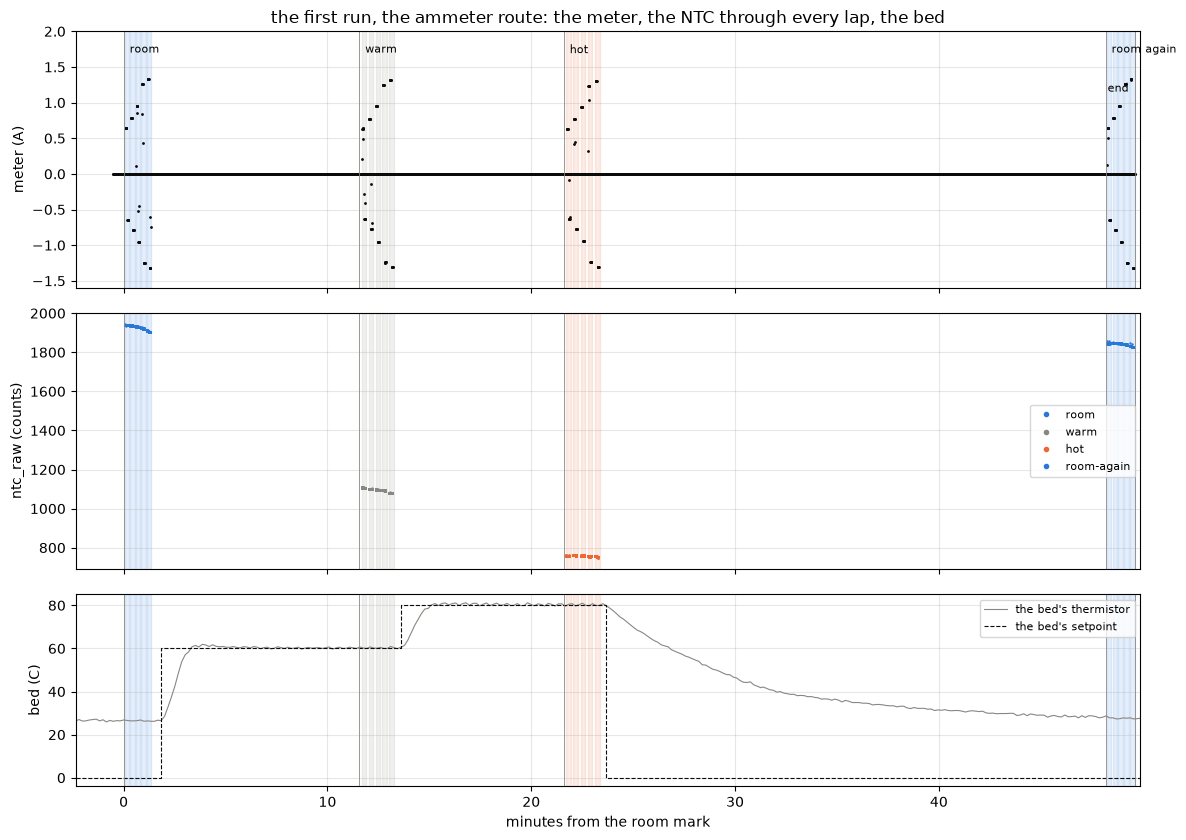

missing rows per lap: {'room': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'warm': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'hot': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'room-again': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}}


In [4]:
SEG_T0 = {0: 0.0, 1: 1.0, 2: 6.0}      # nominal start of each segment inside a lap: 1 s rest, 3 s drive, 2 s rest not streamed, 3 s drive

def lap_trace(root, p, L, step=200):
    # the rows of one lap thinned to every 10 ms, placed on the host clock at the lap's start plus the segment's nominal offset
    df, meta = tel.load(root / p / L["folder"], BOARD)                # checks the sense block against the board entry
    d = df.iloc[::step].copy()
    d["t_host"] = L["t_start"] + d["seg"].map(SEG_T0) + d["tick"] / meta["tick_hz"]
    d["plateau"], d["k"], d["missing"] = p, int(L["k"]), int(tel.gaps(df).sum())
    return d

trace = pd.concat([lap_trace(CAPTURE, L["plateau"], L) for _, L in levels.iterrows()], ignore_index=True)
missing = trace.drop_duplicates(["plateau", "k"]).set_index(["plateau", "k"])["missing"]
fig, ax = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.6, 1.6, 1.2]})
ax[0].plot(tm(dmm["t_host"]), dmm["value"], ".", ms=2, color=INK)
for _, L in levels.iterrows():                                        # each lap's sweep window, in the plateau's colour
    for a in ax:
        a.axvspan(tm(L["t_start"]), tm(L["t_end"]), color=COLOR[L["plateau"]], alpha=0.12)
ax[0].set_ylabel("meter (A)")
for p in PLATEAUS:
    g = trace[trace["plateau"] == p]
    ax[1].plot(tm(g["t_host"]), g["ntc_raw"], ".", ms=1.5, color=COLOR[p], label=p)
ax[1].set_ylabel("ntc_raw (counts)"); ax[1].legend(fontsize=8, loc="center right", markerscale=4)
ax[2].plot(tm(heater["t_host"]), heater["bed_c"], "-", lw=0.8, color=MUTED, label="the bed's thermistor")
ax[2].step(tm(heater["t_host"]), heater["target_c"], where="post", lw=0.8, ls="--", color=INK, label="the bed's setpoint")
ax[2].set_ylabel("bed (C)"); ax[2].legend(fontsize=8, loc="upper right")
for a in ax:
    for _, m in marks.iterrows():                                     # the marks
        a.axvline(tm(m["t_host"]), color=MUTED, lw=0.6)
    a.grid(alpha=0.3)
for _, m in marks.iterrows():                                         # the mark names along the top of the first panel, `end` a row lower and to the left of its line
    end = m["mark"] == "end"
    ax[0].text(tm(m["t_host"]) + (-0.3 if end else 0.3), 0.80 if end else 0.95, m["mark"], fontsize=8, va="top", ha="right" if end else "left", transform=ax[0].get_xaxis_transform())
ax[0].set_ylim(-1.6, 2.0); ax[0].set_title("the first run, the ammeter route: the meter, the NTC through every lap, the bed")
ax[-1].set_xlabel("minutes from the room mark"); ax[-1].set_xlim(tm(heater["t_host"].iloc[0]), tm(heater["t_host"].iloc[-1]))
plt.tight_layout(); plt.show()
print("missing rows per lap:", {p: missing[p].to_dict() for p in PLATEAUS})

The meter reads zero between laps and a stroke each way in every lap, the strokes a little shorter at the warm and hot plateaus. The NTC's count steps down from about 1930 at room to 1100 at warm and 760 at hot, and sits at 1840 at room again, which the next section turns into degrees. The bed sits well over the board at the two heated plateaus, as in ntc-curve, 60 C of bed for about 50 C of board and 80 C for about 63 C, and it sat at 26 to 27 C with its heater off through the room laps, warm from the earlier run, so the first plateau is not the room's 24 C either. No lap of any plateau dropped a row.

The second run the same way, the meter's millivolts across the shunt and the NTC through every lap, with the laps shaded and the marks named. No bed panel, since its log did not record. The thing to see is the same four plateaus on the NTC, with the first one at a true room this time, and the meter's strokes in millivolts where the first run had amps.

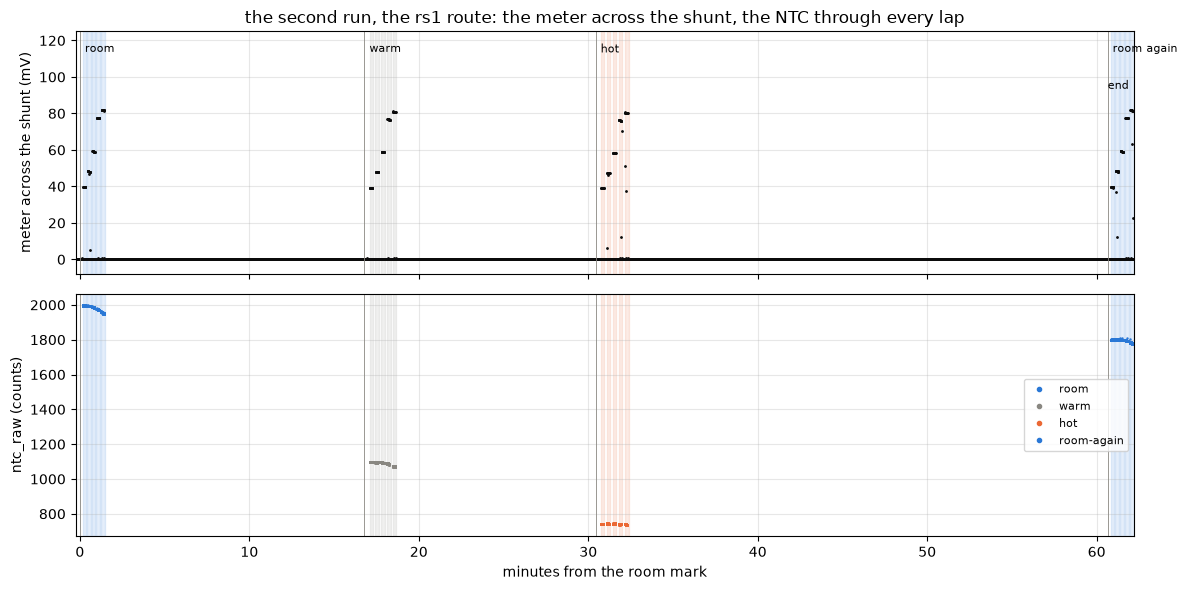

missing rows per lap: {'room': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'warm': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'hot': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'room-again': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}}


In [5]:
trace2 = pd.concat([lap_trace(CAPTURE2, L["plateau"], L) for _, L in levels2.iterrows()], ignore_index=True)   # the second run's laps, thinned, on the host clock
missing2 = trace2.drop_duplicates(["plateau", "k"]).set_index(["plateau", "k"])["missing"]
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(tm2(dmm2["t_host"]), dmm2["value"] * 1e3, ".", ms=2, color=INK)
for _, L in levels2.iterrows():                                       # each lap's sweep window, in the plateau's color
    for a in ax:
        a.axvspan(tm2(L["t_start"]), tm2(L["t_end"]), color=COLOR[L["plateau"]], alpha=0.12)
ax[0].set_ylabel("meter across the shunt (mV)")
for p in PLATEAUS:
    g_ = trace2[trace2["plateau"] == p]
    ax[1].plot(tm2(g_["t_host"]), g_["ntc_raw"], ".", ms=1.5, color=COLOR[p], label=p)
ax[1].set_ylabel("ntc_raw (counts)"); ax[1].legend(fontsize=8, loc="center right", markerscale=4)
for a in ax:
    for _, m in marks2.iterrows():                                    # the marks
        a.axvline(tm2(m["t_host"]), color=MUTED, lw=0.6)
    a.grid(alpha=0.3)
for _, m in marks2.iterrows():                                        # the mark names along the top of the first panel, `end` a row lower and to the left of its line
    end = m["mark"] == "end"
    ax[0].text(tm2(m["t_host"]) + (-0.3 if end else 0.3), 0.80 if end else 0.95, m["mark"], fontsize=8, va="top", ha="right" if end else "left", transform=ax[0].get_xaxis_transform())
ax[0].set_ylim(-8, 125); ax[0].set_title("the second run, the rs1 route: the meter across the shunt, the NTC through every lap")
ax[-1].set_xlabel("minutes from the room mark"); ax[-1].set_xlim(tm2(dmm2["t_host"].iloc[0]), tm2(dmm2["t_host"].iloc[-1]))
plt.tight_layout(); plt.show()
print("missing rows per lap:", {p: missing2[p].to_dict() for p in PLATEAUS})

The meter reads a stroke each way of 40 to 82 mV of shunt, the same shape as the amps the day before, and positive in both directions as the counts are, since the shunt carries the bridge's return current whichever way the load is driven. The NTC steps from about 1980 counts at room to 1090 at warm and 740 at hot, and sits at 1800 at room again. The first plateau sits 50 counts over the first run's, about a degree cooler, which is the bed off at the room's 24 C instead of warm from an earlier run. No lap of any plateau dropped a row.

## Method

Each plateau's laps give counts over the lap's own torque-off zero against the meter's amps, as in current-scale, and a straight line through its ten points, $n = b + G \, I$, is that plateau's gain $G$ in counts per amp and in-drive offset $b$ in counts. The board temperature of a plateau is the mean of its laps' NTC readings during the drive, converted by the beta equation at the nominal beta from the ntc-curve result, its design conversion, with the spread over the laps as its bracket. The gain at each plateau against the first room plateau, in percent, is the drift, and read through copper's 0.39 % per degree it is the winding temperature a hold would misread by. The torque-off zero of each plateau is read the same way in counts.

The drift per degree is the slope of a line through the four plateaus' drift against their board temperature, with the standard error of that line from the residuals of four points. Two of the four sit near one temperature, so the line's lever arm is the room to hot span and the fourth point mostly reads the return. Two other estimators are run as checks. One pools all forty rows into one model, $n = b + G \, I \, (1 + c \, (T - T_0))$, with one offset for the run and $c$ as the drift per degree, which uses the within-plateau scatter for its error. The other takes each lap's counts over amps against the room lap at the same level and direction, a per-lap ratio that needs no intercept, and reads the drift at each plateau as the mean of ten such ratios with the standard error of that mean.

The meter's class on the 20 A range, 2 % of the reading plus 25 mA, does not enter the drift. A gain error of the meter is the same at every plateau and divides out of a ratio of gains on the same meter in one sitting. What does enter is the meter's repeatability, its 1 mA steps and whatever of the fixed term moves within an hour, and both are inside the fit's residual, so the drift is bounded by the fit's standard error and not by the class. The absolute gain at any plateau carries the class as before.

A plateau temperature through the nominal beta carries ntc-curve's grade. The meter's class there is 1 % of the reading plus 0.5 C, 1.1 C at the hot plateau, and the bed heating the board from below left the top surface, and the thermocouple that graded the curve, under the NTC's copper by about 0.06 C per C the bed sat over the board, 1.1 C at the hot plateau here with the bed 18 C over it. Together that is about 2 C on the hot plateau's temperature, which moves a per-degree slope over the 35 C span by about 6 % and nothing else here. The drift is also drawn against the raw NTC count, which needs no curve at all.

The second capture is read the same way with the shunt's millivolts in place of the amps. A line through each plateau's ten points, $n = b + A \, V$, is that plateau's amplifier $A$ in counts per millivolt of shunt and its offset $b$ in counts, and the same three estimators give its drift per degree, the line through the four plateaus, the pooled model over all forty rows and the per-lap ratio against the room lap at the same level and direction. The meter's class on the 220 mV range, 0.1 % of the reading plus 50 uV, divides out of a ratio of gains the way the 20 A jack's does, and its 10 uV steps are 0.012 % of an 82 mV reading, so the amplifier's drift is bounded by the fit's standard error again.

VDD at each plateau is the chip's 1.2 V reference as the ADC reads it over the rest stream, VDD = 1.2 V x 4096 / vref_raw, the mean over the stream with the stream's standard deviation as its spread. The ADC's reference is VDD, so counts per millivolt scale as one over VDD, and a VDD rise of x percent takes x percent off the counts. The amplifier's drift with that share put back is the op-amp and its two resistors on their own.

The chain is the shunt times the amplifier and the ADC, so a ratio of chain gains at two temperatures is the shunt's ratio times the amplifier's, and in percent the chain's drift from the first capture less the amplifier's from the second is the shunt's own resistance change, with the two standard errors added in quadrature. The shunt's rating, 50 ppm per C either way from the registry, is 0.005 % per C and is the band the difference is compared with.

### The lap table

The first capture, one row per lap and direction, every plateau, the meter joined by its driven stretches.

In [6]:
def ntc_c(raw):
    # the NTC's temperature in degrees C from its raw count, the beta equation at the nominal beta, ntc-curve's design conversion
    return 1 / (1 / 298.15 + np.log(BOARD.ntc_ohm(np.asarray(raw, float)) / BOARD.ntc_r25_ohm) / BETA) - 273.15

tables = {p: laps.table(CAPTURE / p, BOARD, dmm).assign(plateau=p) for p in PLATEAUS}   # the settled means, the rest zero, the meter's median per direction
T = pd.concat(tables.values(), ignore_index=True)
T["counts"] = T["current_raw"] - T["zero"]                            # n, counts over the lap's own rest zero
T["amps"] = T["meter"].abs()                                          # I, the meter's current, unsigned
T["board_c"] = ntc_c(T["ntc_raw"])                                    # the board during that direction's drive
show(T[["plateau", "k", "volts_set", "vsys_read", "dir", "zero", "current_raw", "counts", "current_sd", "meter", "meter_n", "ntc_raw", "board_c"]], n=None)
room = T[T["plateau"] == "room"].set_index(["k", "dir"])
for p in PLATEAUS:                                                    # the load's current at each plateau against room at the same level and direction
    t = T[T["plateau"] == p].set_index(["k", "dir"])
    print(f"{p:10s} {t['amps'].min():.3f} to {t['amps'].max():.3f} A, meter packets per point {t['meter_n'].min()} to {t['meter_n'].max()}, "
          f"current against the room lap at the same level {((t['amps'] / room['amps'] - 1) * 100).mean():+.2f} %, board {t['board_c'].min():.1f} to {t['board_c'].max():.1f} C, "
          f"in-lap sd {t['current_sd'].min():.1f} to {t['current_sd'].max():.1f} counts")

,plateau,k,volts_set,vsys_read,dir,zero,current_raw,counts,current_sd,meter,meter_n,ntc_raw,board_c
0,room,0,3.700,3.698,1,1207.000,1940.974,733.974,1.322,0.641,6,1940.206,27.390
1,room,0,3.700,3.698,-1,1207.000,1938.964,731.964,1.324,-0.641,6,1940.154,27.391
2,room,1,4.500,4.503,1,1207.000,2100.698,893.698,1.448,0.783,6,1938.172,27.436
3,room,1,4.500,4.503,-1,1207.000,2098.118,891.118,1.506,-0.782,6,1936.580,27.471
4,room,2,5.500,5.516,1,1207.000,2301.166,1094.166,1.497,0.958,6,1931.966,27.575
5,room,2,5.500,5.516,-1,1207.000,2298.426,1091.426,1.462,-0.957,7,1929.759,27.624
6,room,3,7.200,7.203,1,1207.000,2640.491,1433.491,2.098,1.256,7,1923.952,27.755
7,room,3,7.200,7.203,-1,1207.000,2635.778,1428.778,2.011,-1.255,6,1919.884,27.846
8,room,4,7.600,7.583,1,1207.000,2717.323,1510.323,2.078,1.327,6,1909.914,28.071
9,room,4,7.600,7.583,-1,1207.000,2712.682,1505.682,2.014,-1.324,7,1904.473,28.193


room       0.641 to 1.327 A, meter packets per point 6 to 7, current against the room lap at the same level +0.00 %, board 27.4 to 28.2 C, in-lap sd 1.3 to 2.1 counts
warm       0.636 to 1.313 A, meter packets per point 6 to 7, current against the room lap at the same level -0.93 %, board 49.2 to 50.1 C, in-lap sd 1.4 to 2.4 counts
hot        0.629 to 1.307 A, meter packets per point 6 to 7, current against the room lap at the same level -1.53 %, board 62.3 to 62.8 C, in-lap sd 1.2 to 2.6 counts
room-again 0.640 to 1.325 A, meter packets per point 6 to 6, current against the room lap at the same level -0.06 %, board 29.5 to 29.9 C, in-lap sd 1.3 to 2.1 counts


Forty points, ten per plateau, 0.63 to 1.33 A. The meter gives six or seven packets per direction, and the current channel's standard deviation inside a lap is 1.2 to 2.6 counts, as in current-scale. The current at a level falls 0.9 % at the warm plateau and 1.5 % at the hot one against room, which is the load warming on the bed, and comes back at room again. The board temperature through the nominal beta is 27.7, 49.5, 62.6 and 29.6 C at the four plateaus, each moving under a degree across its five laps.

## Results

### Gain and offset per plateau, the chain

The first capture. Counts over the lap's own zero against the meter's amps, every lap of every plateau, with one line through all forty points, and under it the residuals from that line by plateau with each plateau's own line dotted through them. The thing to see is the warm and hot points sitting under the room points at the top of the range, which is the quarter percent.

,plateau,board_c,c_lo,c_hi,ntc_raw,gain,gain_se,offset,offset_se,rms,zero,zero_lo,zero_hi,laps,gain_pct,gain_pct_se,copper_c
0,room,27.675,27.390,28.193,1927.506,1134.665,1.938,5.478,1.990,1.447,1207.000,1207.000,1207.000,10,0.000,0.171,0.000
1,warm,49.542,49.165,50.068,1095.512,1132.043,2.053,6.214,2.087,1.514,1209.000,1209.000,1209.000,10,-0.231,0.181,-0.592
2,hot,62.573,62.345,62.807,757.841,1131.630,1.987,5.504,2.010,1.465,1209.000,1208.000,1210.000,10,-0.267,0.176,-0.686
3,room-again,29.624,29.500,29.942,1841.519,1135.059,1.331,5.125,1.366,0.992,1207.200,1207.000,1208.000,10,0.035,0.117,0.089


all forty points: G 1133.5 +/- 1.2 counts/A, b +5.5 +/- 1.2 counts, rms 1.91; current-scale at room 1135.0 +/- 1.2, b +5.3
room       board 27.7 C  G 1134.7 +/- 1.9 counts/A (+0.00 % against room, +/- 0.17)  b +5.5 +/- 2.0 counts  rms 1.45  zero 1207.0 (1207 to 1207)  copper +0.00 C
warm       board 49.5 C  G 1132.0 +/- 2.1 counts/A (-0.23 % against room, +/- 0.18)  b +6.2 +/- 2.1 counts  rms 1.51  zero 1209.0 (1209 to 1209)  copper -0.59 C
hot        board 62.6 C  G 1131.6 +/- 2.0 counts/A (-0.27 % against room, +/- 0.18)  b +5.5 +/- 2.0 counts  rms 1.46  zero 1209.0 (1208 to 1210)  copper -0.69 C
room-again board 29.6 C  G 1135.1 +/- 1.3 counts/A (+0.03 % against room, +/- 0.12)  b +5.1 +/- 1.4 counts  rms 0.99  zero 1207.2 (1207 to 1208)  copper +0.09 C


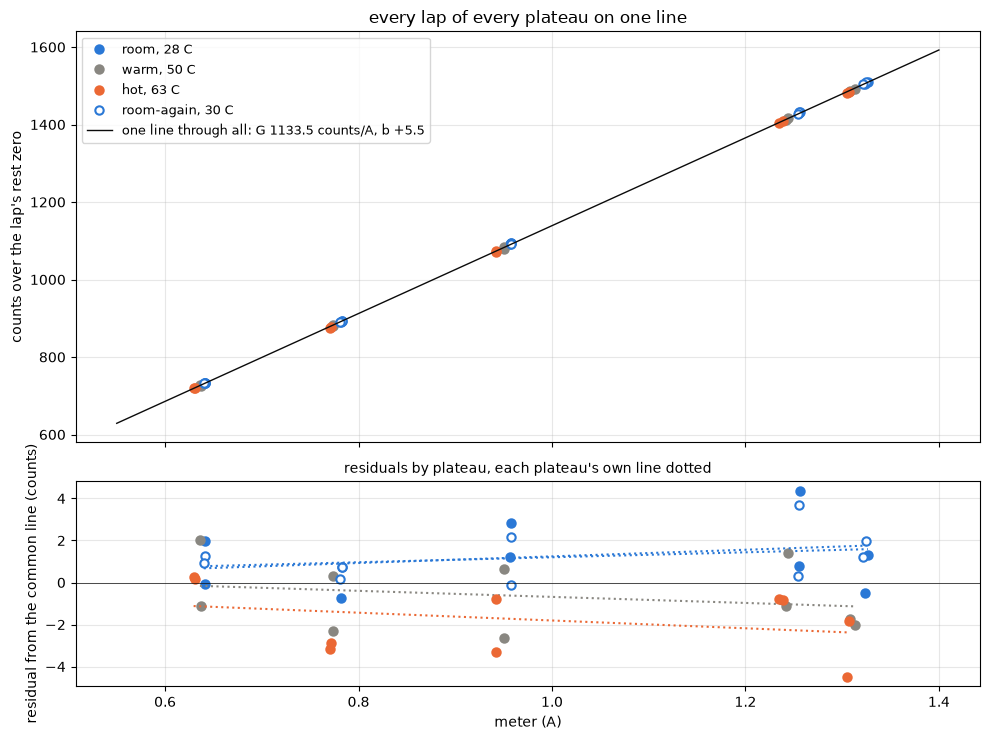

In [7]:
rows = []
for p in PLATEAUS:
    t = T[T["plateau"] == p]
    f = laps.line(t["amps"], t["counts"])                             # that plateau's line, with the standard errors
    rows.append({"plateau": p, "board_c": t["board_c"].mean(), "c_lo": t["board_c"].min(), "c_hi": t["board_c"].max(), "ntc_raw": t["ntc_raw"].mean(),
                 "gain": f["slope"], "gain_se": f["slope_se"], "offset": f["intercept"], "offset_se": f["intercept_se"], "rms": f["rms"],
                 "zero": t["zero"].mean(), "zero_lo": t["zero"].min(), "zero_hi": t["zero"].max(), "laps": len(t)})
P = pd.DataFrame(rows)
P["gain_pct"] = (P["gain"] / P["gain"].iloc[0] - 1) * 100             # the drift against the first room plateau
P["gain_pct_se"] = P["gain_se"] / P["gain"] * 100                     # each plateau's own standard error, in percent
P["copper_c"] = P["gain_pct"] / COPPER_PCT_PER_C                      # that drift read as winding temperature
show(P, n=None)
fit_all = laps.line(T["amps"], T["counts"])                           # one line through all forty points, the reference for the residual panel
T["resid"] = T["counts"] - (fit_all["slope"] * T["amps"] + fit_all["intercept"])
print(f"all forty points: G {fit_all['slope']:.1f} +/- {fit_all['slope_se']:.1f} counts/A, b {fit_all['intercept']:+.1f} +/- {fit_all['intercept_se']:.1f} counts, rms {fit_all['rms']:.2f}; "
      f"current-scale at room {CS['counts_per_a']['value']:.1f} +/- {CS['counts_per_a']['value'] - CS['counts_per_a']['lo']:.1f}, b {CS['drive_offset_counts']['value']:+.1f}")
for _, r in P.iterrows():
    print(f"{r['plateau']:10s} board {r['board_c']:.1f} C  G {r['gain']:.1f} +/- {r['gain_se']:.1f} counts/A ({r['gain_pct']:+.2f} % against room, +/- {r['gain_pct_se']:.2f})  "
          f"b {r['offset']:+.1f} +/- {r['offset_se']:.1f} counts  rms {r['rms']:.2f}  zero {r['zero']:.1f} ({r['zero_lo']:.0f} to {r['zero_hi']:.0f})  copper {r['copper_c']:+.2f} C")
fig, ax = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.linspace(0.55, 1.4, 10)
for p in PLATEAUS:
    t = T[T["plateau"] == p]; r = P[P["plateau"] == p].iloc[0]
    kw = dict(ls="none", marker="o", ms=6, color=COLOR[p], mfc=FACE[p], mew=1.5)
    ax[0].plot(t["amps"], t["counts"], label=f"{p}, {r['board_c']:.0f} C", **kw)
    ax[1].plot(t["amps"], t["resid"], **kw)
    xp = np.linspace(t["amps"].min(), t["amps"].max(), 5)             # that plateau's own line, as a residual from the common one
    ax[1].plot(xp, r["gain"] * xp + r["offset"] - (fit_all["slope"] * xp + fit_all["intercept"]), ":", color=COLOR[p], lw=1.5)
ax[0].plot(x, fit_all["slope"] * x + fit_all["intercept"], "-", color=INK, lw=1, label=f"one line through all: G {fit_all['slope']:.1f} counts/A, b {fit_all['intercept']:+.1f}")
ax[0].set_ylabel("counts over the lap's rest zero"); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3); ax[0].set_title("every lap of every plateau on one line")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("residual from the common line (counts)"); ax[1].set_xlabel("meter (A)"); ax[1].grid(alpha=0.3)
ax[1].set_title("residuals by plateau, each plateau's own line dotted", fontsize=10)
plt.tight_layout(); plt.show()

The forty points lie on one line to the eye, and one line through all of them gives 1133.5 +/- 1.2 counts per amp with an offset of +5.5 counts and a residual of 1.9 counts rms, the current-scale numbers again with a little more scatter. The residual panel is where the plateaus part. The room and room-again points sit one to two counts over the common line at 1.3 A and the warm and hot points two to four counts under it, with the dotted lines fanning out from near zero at 0.6 A, which is a gain difference and not an offset. Each plateau's own line gives 1134.7 +/- 1.9 at room, 1132.0 +/- 2.1 at warm, 1131.6 +/- 2.0 at hot and 1135.1 +/- 1.3 at room again, a fall of 0.23 and 0.27 % at the two heated plateaus and a return to +0.03 % at room again. The offsets are +5.5, +6.2, +5.5 and +5.1 counts, each +/- 2, so the offset does not move with temperature to within its error, and the zero is 1207 counts at the two room plateaus and 1209 at the two heated ones.

### The chain's drift against board temperature

The first capture. The gain's drift at each plateau against the board temperature with its own standard error, the line through the four points, and a band of two degrees of copper for scale. The same drift against the raw NTC count, which needs no curve. And the torque-off zero against board temperature. The thing to see is whether the drift follows the temperature and comes back with it.

line through the four plateaus: gain -0.0090 +/- 0.0017 % per C over 28 to 63 C, rms 0.035 %; zero +0.062 +/- 0.015 counts per C; against the raw count +0.0266 +/- 0.0041 % per 100 counts
pooled model over all forty rows, one offset: G 1134.7 +/- 0.9 counts/A at 27.7 C, b +5.5 +/- 0.9, drift -0.0080 +/- 0.0014 % per C, rms 1.37 counts
per-lap ratio against the room lap at the same level: room +0.00 +/- 0.00 %, warm -0.15 +/- 0.03 %, hot -0.25 +/- 0.05 %, room-again +0.00 +/- 0.03 %
room again against room: +0.03 +/- 0.21 %; hot against room -0.27 % over 34.9 C, -0.69 C of copper; per degree of board -0.0230 C of winding
a plateau temperature's own uncertainty: the meter's class 1.1 C at the hot plateau and the bed gradient 1.1 C with the bed 18 C over the board, together 2.2 C on a 34.9 C span, about 6 % on the slope


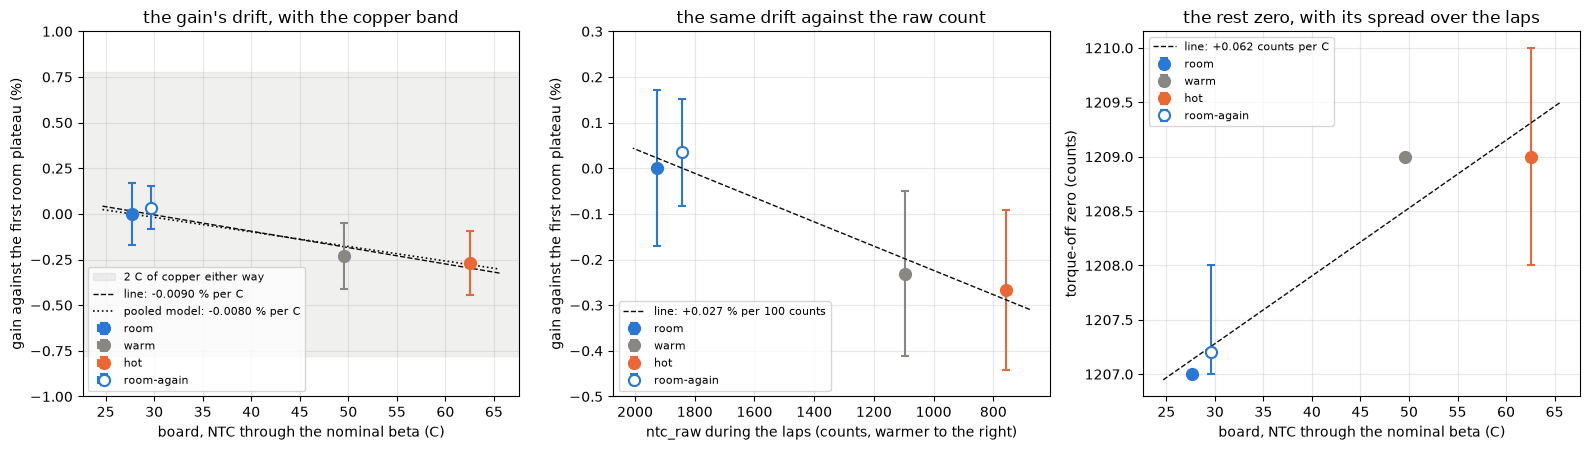

In [8]:
g = laps.line(P["board_c"], P["gain_pct"])                            # the drift per degree, a line through the four plateaus
z = laps.line(P["board_c"], P["zero"])                                # the zero per degree, the same way
rl = laps.line(P["ntc_raw"], P["gain_pct"])                            # the drift per raw count, no curve in it
T0_C = P["board_c"].iloc[0]
X = np.column_stack([np.ones(len(T)), T["amps"], T["amps"] * (T["board_c"] - T0_C)])   # the pooled model: n = b + G I + G c I (T - T0)
coef, *_ = np.linalg.lstsq(X, T["counts"].to_numpy(float), rcond=None)
res = T["counts"].to_numpy(float) - X @ coef
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (res @ res) / (len(T) - 3))
pooled, pooled_se = coef[2] / coef[1] * 100, se[2] / coef[1] * 100     # c in percent per degree, with its standard error
ratio = {}
for p in PLATEAUS:                                                    # each lap's counts per amp against the room lap at the same level and direction
    t = T[T["plateau"] == p].set_index(["k", "dir"])
    q = ((t["counts"] / t["amps"]) / (room["counts"] / room["amps"]) - 1) * 100
    ratio[p] = (q.mean(), q.std() / np.sqrt(len(q)))
back = P["gain_pct"].iloc[3]; back_se = np.hypot(P["gain_pct_se"].iloc[0], P["gain_pct_se"].iloc[3])   # room again against room, both errors in it
span = P["board_c"].iloc[2] - P["board_c"].iloc[0]
print(f"line through the four plateaus: gain {g['slope']:+.4f} +/- {g['slope_se']:.4f} % per C over {P['board_c'].min():.0f} to {P['board_c'].max():.0f} C, rms {g['rms']:.3f} %; "
      f"zero {z['slope']:+.3f} +/- {z['slope_se']:.3f} counts per C; against the raw count {rl['slope'] * 100:+.4f} +/- {rl['slope_se'] * 100:.4f} % per 100 counts")
print(f"pooled model over all forty rows, one offset: G {coef[1]:.1f} +/- {se[1]:.1f} counts/A at {T0_C:.1f} C, b {coef[0]:+.1f} +/- {se[0]:.1f}, drift {pooled:+.4f} +/- {pooled_se:.4f} % per C, rms {np.sqrt((res ** 2).mean()):.2f} counts")
print("per-lap ratio against the room lap at the same level: " + ", ".join(f"{p} {m:+.2f} +/- {s:.2f} %" for p, (m, s) in ratio.items()))
print(f"room again against room: {back:+.2f} +/- {back_se:.2f} %; hot against room {P['gain_pct'].iloc[2]:+.2f} % over {span:.1f} C, "
      f"{P['copper_c'].iloc[2]:+.2f} C of copper; per degree of board {g['slope'] / COPPER_PCT_PER_C:+.4f} C of winding")
hot_laps = levels[levels["plateau"] == "hot"]
bed_hot = heater[heater["t_host"].between(hot_laps["t_start"].min(), hot_laps["t_end"].max())]["bed_c"].mean()   # the bed's thermistor through the hot laps
class_hot = DMM["accuracy"]["temp_c"]["pct"]["value"] / 100 * P["board_c"].iloc[2] + DMM["accuracy"]["temp_c"]["fixed"]["value"]   # the meter's class at the hot plateau, the grade behind the curve
grad_hot = NC["gradient_c_per_c"]["value"] * (bed_hot - P["board_c"].iloc[2])    # the bed gradient ntc-curve names, per C the bed sits over the board
print(f"a plateau temperature's own uncertainty: the meter's class {class_hot:.1f} C at the hot plateau and the bed gradient {grad_hot:.1f} C with the bed "
      f"{bed_hot - P['board_c'].iloc[2]:.0f} C over the board, together {class_hot + grad_hot:.1f} C on a {span:.1f} C span, about {(class_hot + grad_hot) / span * 100:.0f} % on the slope")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
tt = np.linspace(P["board_c"].min() - 3, P["board_c"].max() + 3, 10)
ax[0].axhspan(-COPPER_PCT_PER_C * 2, COPPER_PCT_PER_C * 2, color=MUTED, alpha=0.12, label="2 C of copper either way")
ax[0].plot(tt, g["slope"] * tt + g["intercept"], "--", color=INK, lw=1, label=f"line: {g['slope']:+.4f} % per C")
ax[0].plot(tt, pooled * (tt - T0_C), ":", color=INK, lw=1.2, label=f"pooled model: {pooled:+.4f} % per C")
rr = np.linspace(P["ntc_raw"].min() - 80, P["ntc_raw"].max() + 80, 10)
for _, p_ in P.iterrows():
    p = p_["plateau"]; kw = dict(fmt="o", ms=8, color=COLOR[p], mfc=FACE[p], mew=1.5, capsize=3, label=p)
    ax[0].errorbar(p_["board_c"], p_["gain_pct"], yerr=p_["gain_pct_se"], xerr=[[p_["board_c"] - p_["c_lo"]], [p_["c_hi"] - p_["board_c"]]], **kw)
    ax[1].errorbar(p_["ntc_raw"], p_["gain_pct"], yerr=p_["gain_pct_se"], **kw)
    ax[2].errorbar(p_["board_c"], p_["zero"], yerr=[[p_["zero"] - p_["zero_lo"]], [p_["zero_hi"] - p_["zero"]]], **kw)
ax[1].plot(rr, rl["slope"] * rr + rl["intercept"], "--", color=INK, lw=1, label=f"line: {rl['slope'] * 100:+.3f} % per 100 counts")
ax[2].plot(tt, z["slope"] * tt + z["intercept"], "--", color=INK, lw=1, label=f"line: {z['slope']:+.3f} counts per C")
ax[0].set_ylim(-1.0, 1.0); ax[0].set_xlabel("board, NTC through the nominal beta (C)"); ax[0].set_ylabel("gain against the first room plateau (%)"); ax[0].set_title("the gain's drift, with the copper band")
ax[1].set_ylim(-0.5, 0.3); ax[1].invert_xaxis(); ax[1].set_xlabel("ntc_raw during the laps (counts, warmer to the right)"); ax[1].set_ylabel("gain against the first room plateau (%)"); ax[1].set_title("the same drift against the raw count")
ax[2].set_xlabel("board, NTC through the nominal beta (C)"); ax[2].set_ylabel("torque-off zero (counts)"); ax[2].set_title("the rest zero, with its spread over the laps")
for a, loc in zip(ax, ("lower left", "lower left", "upper left")):
    a.grid(alpha=0.3); a.legend(fontsize=8, loc=loc)
plt.tight_layout(); plt.show()

Left, the gain falls as the board warms and comes back when it cools, with the two heated plateaus at -0.23 and -0.27 % and the two room plateaus within 0.04 % of each other. The line through the four gives -0.0090 +/- 0.0017 % per C over 28 to 63 C, and the whole excursion sits well inside the band of two degrees of copper, at -0.69 C of winding at the hot plateau. The middle panel reads the same thing off the raw count, +0.027 % per 100 counts with the count falling as the board warms, so the finding does not lean on the curve. The pooled model's dotted line sits on the four-point line in the left panel. Right, the zero sits at 1207 counts at both room plateaus and 1209 at both heated ones, +0.06 counts per C, about 2 counts over the span, which is 1.8 mA at this gain.

The checks agree with the line. The pooled model over all forty rows with one offset gives -0.0080 +/- 0.0014 % per C with a residual of 1.4 counts rms, the within-plateau noise. The per-lap ratios against the room lap at the same level, zero at room by construction, give -0.15 +/- 0.03 % at warm, -0.25 +/- 0.05 % at hot and +0.00 +/- 0.03 % at room again. That last estimator needs no intercept and puts the hot plateau five standard errors under room, so the fall is in the data with high confidence, and its return at room again puts it with the temperature and not with the hour. Its size is a quarter percent over about 35 C of board, with the four-point line's standard error of 0.002 % per C as the bracket and about 6 % more on top from the plateau temperatures' own uncertainty, the meter's class and the bed gradient behind ntc-curve's grade. The per-plateau gains each carry a standard error of 0.17 to 0.18 %, which is most of the signal, so one plateau on its own does not read the drift and the four together do.

### The amplifier and the ADC alone

The second capture's laps, counts over the lap's own zero against the shunt's millivolts as the meter read them, one row per lap and direction with the meter joined by its driven stretches, the first capture's table again on the other route.

In [9]:
tables2 = {p: laps.table(CAPTURE2 / p, BOARD, dmm2).assign(plateau=p) for p in PLATEAUS}   # the settled means, the rest zero, the meter's median per direction in volts
T2 = pd.concat(tables2.values(), ignore_index=True)
T2["counts"] = T2["current_raw"] - T2["zero"]                         # n, counts over the lap's own rest zero
T2["mv"] = T2["meter"].abs() * 1e3                                    # V, the shunt's own drop as the meter read it, unsigned, in millivolts
T2["board_c"] = ntc_c(T2["ntc_raw"])                                  # the board during that direction's drive
show(T2[["plateau", "k", "volts_set", "vsys_read", "dir", "zero", "current_raw", "counts", "current_sd", "meter", "meter_n", "ntc_raw", "board_c"]], n=None)
room2 = T2[T2["plateau"] == "room"].set_index(["k", "dir"])
for p in PLATEAUS:                                                    # the shunt's millivolts at each plateau against room at the same level and direction
    t = T2[T2["plateau"] == p].set_index(["k", "dir"])
    print(f"{p:10s} {t['mv'].min():.1f} to {t['mv'].max():.1f} mV, meter packets per point {t['meter_n'].min()} to {t['meter_n'].max()}, "
          f"shunt millivolts against the room lap at the same level {((t['mv'] / room2['mv'] - 1) * 100).mean():+.2f} %, board {t['board_c'].min():.1f} to {t['board_c'].max():.1f} C, "
          f"in-lap sd {t['current_sd'].min():.1f} to {t['current_sd'].max():.1f} counts")
print("the first capture's plateaus for comparison: " + ", ".join(f"{r['plateau']} {r['board_c']:.1f} C at {r['ntc_raw']:.0f} counts" for _, r in P.iterrows()))

,plateau,k,volts_set,vsys_read,dir,zero,current_raw,counts,current_sd,meter,meter_n,ntc_raw,board_c
0,room,0,3.700,3.700,1,1206.000,1947.321,741.321,1.263,0.040,6,1997.023,26.125
1,room,0,3.700,3.700,-1,1206.000,1945.395,739.395,1.274,0.040,6,1996.570,26.135
2,room,1,4.500,4.506,1,1206.000,2108.911,902.911,1.504,0.048,6,1994.038,26.191
3,room,1,4.500,4.506,-1,1206.000,2106.465,900.465,1.380,0.048,6,1992.165,26.232
4,room,2,5.500,5.507,1,1207.000,2313.825,1106.825,1.546,0.059,6,1987.227,26.342
5,room,2,5.500,5.507,-1,1207.000,2310.808,1103.808,1.555,0.059,6,1983.721,26.420
6,room,3,7.200,7.200,1,1207.000,2655.705,1448.705,2.219,0.078,6,1975.815,26.596
7,room,3,7.200,7.200,-1,1207.000,2651.237,1444.237,1.768,0.077,6,1971.242,26.697
8,room,4,7.600,7.601,1,1207.000,2734.190,1527.190,2.164,0.082,6,1958.660,26.978
9,room,4,7.600,7.601,-1,1207.000,2730.169,1523.169,1.998,0.082,6,1952.176,27.122


room       39.6 to 81.9 mV, meter packets per point 6 to 6, shunt millivolts against the room lap at the same level +0.00 %, board 26.1 to 27.1 C, in-lap sd 1.3 to 2.2 counts
warm       39.3 to 81.0 mV, meter packets per point 6 to 6, shunt millivolts against the room lap at the same level -0.86 %, board 49.4 to 50.3 C, in-lap sd 1.2 to 2.5 counts
hot        39.0 to 80.4 mV, meter packets per point 6 to 7, shunt millivolts against the room lap at the same level -1.56 %, board 63.2 to 63.6 C, in-lap sd 1.3 to 2.7 counts
room-again 39.7 to 81.8 mV, meter packets per point 6 to 7, shunt millivolts against the room lap at the same level +0.04 %, board 30.5 to 31.1 C, in-lap sd 1.3 to 2.2 counts
the first capture's plateaus for comparison: room 27.7 C at 1928 counts, warm 49.5 C at 1096 counts, hot 62.6 C at 758 counts, room-again 29.6 C at 1842 counts


Forty points again, ten per plateau, 39 to 82 mV of shunt, which is the same 0.63 to 1.33 A through a 60 mOhm part. Six or seven meter packets per direction, and the current channel's in-lap standard deviation is 1.2 to 2.7 counts, as before. The shunt's millivolts at a level fall 0.9 % at warm and 1.6 % at hot against room, as the amps did the day before, the load warming on the bed. The board through the nominal beta is 26.5, 49.7, 63.4 and 30.7 C at the four plateaus, a true room at the first, the hot plateau 0.8 C over the first capture's and the span two degrees longer.

### The amplifier per plateau

Every lap of every plateau on one line, now against the shunt's millivolts, with the residuals by plateau under it and each plateau's own line dotted through them. The thing to see is whether the warm and hot points sit under the room points at the top of the range the way they did with the shunt in the route.

,plateau,board_c,c_lo,c_hi,ntc_raw,amp,amp_se,offset,offset_se,rms,zero,zero_lo,zero_hi,laps,amp_pct,amp_pct_se
0,room,26.484,26.125,27.122,1980.864,18.627,0.022,3.151,1.372,0.997,1206.600,1206.000,1207.000,10,0.000,0.116
1,warm,49.748,49.437,50.344,1089.275,18.609,0.023,3.486,1.464,1.059,1208.400,1208.000,1209.000,10,-0.096,0.125
2,hot,63.351,63.160,63.629,741.180,18.622,0.020,2.453,1.269,0.917,1209.600,1209.000,1210.000,10,-0.027,0.109
3,room-again,30.679,30.526,31.063,1795.708,18.654,0.019,1.710,1.180,0.855,1207.000,1207.000,1207.000,10,0.145,0.100


all forty points: A 18.629 +/- 0.011 counts/mV, b +2.65 +/- 0.71 counts, rms 1.12; nominal 18.474; current-scale's rs1 pass at room 18.654 +/- 0.019, b +1.55
room       board 26.5 C  A 18.627 +/- 0.022 counts/mV (+0.00 % against room, +/- 0.12)  b +3.15 +/- 1.37 counts  rms 1.00  zero 1206.6 (1206 to 1207)
warm       board 49.7 C  A 18.609 +/- 0.023 counts/mV (-0.10 % against room, +/- 0.13)  b +3.49 +/- 1.46 counts  rms 1.06  zero 1208.4 (1208 to 1209)
hot        board 63.4 C  A 18.622 +/- 0.020 counts/mV (-0.03 % against room, +/- 0.11)  b +2.45 +/- 1.27 counts  rms 0.92  zero 1209.6 (1209 to 1210)
room-again board 30.7 C  A 18.654 +/- 0.019 counts/mV (+0.15 % against room, +/- 0.10)  b +1.71 +/- 1.18 counts  rms 0.86  zero 1207.0 (1207 to 1207)


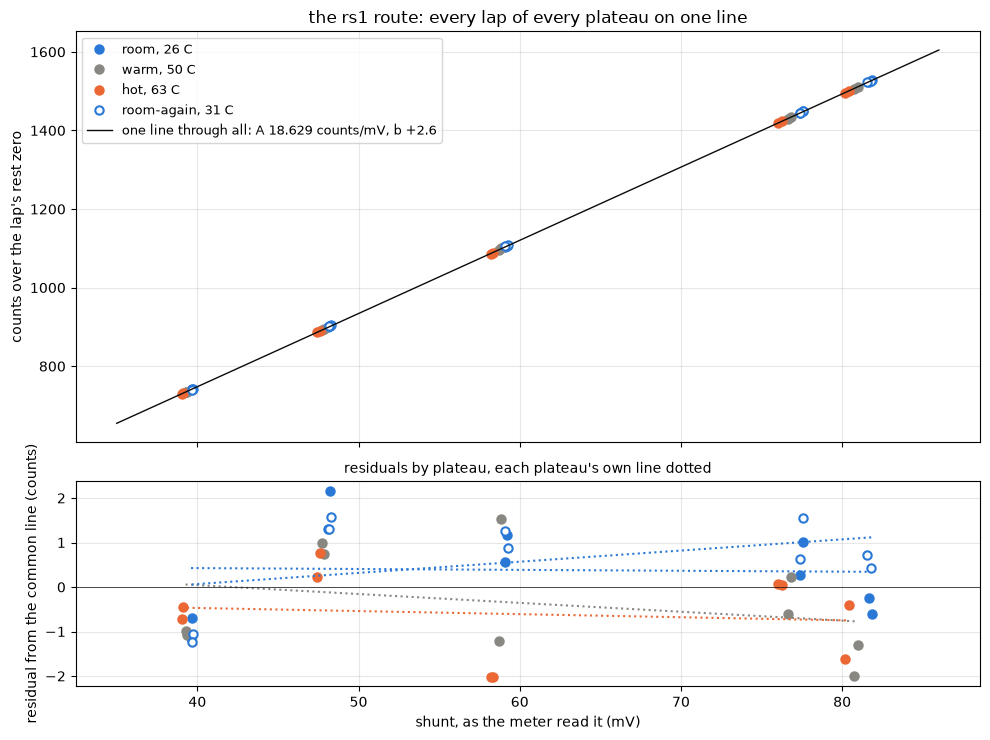

In [10]:
rows = []
for p in PLATEAUS:
    t = T2[T2["plateau"] == p]
    f = laps.line(t["mv"], t["counts"])                                # that plateau's line, counts against the shunt's millivolts
    rows.append({"plateau": p, "board_c": t["board_c"].mean(), "c_lo": t["board_c"].min(), "c_hi": t["board_c"].max(), "ntc_raw": t["ntc_raw"].mean(),
                 "amp": f["slope"], "amp_se": f["slope_se"], "offset": f["intercept"], "offset_se": f["intercept_se"], "rms": f["rms"],
                 "zero": t["zero"].mean(), "zero_lo": t["zero"].min(), "zero_hi": t["zero"].max(), "laps": len(t)})
P2 = pd.DataFrame(rows)
P2["amp_pct"] = (P2["amp"] / P2["amp"].iloc[0] - 1) * 100             # the amplifier's drift against the first room plateau
P2["amp_pct_se"] = P2["amp_se"] / P2["amp"] * 100                     # each plateau's own standard error, in percent
NOM_MV = BOARD.gain_milli / 1e3 * BOARD.adc_counts / BOARD.vdd_mv     # the nominal counts per millivolt of shunt: the gain over the 3.3 V reference
show(P2, n=None)
fit_all2 = laps.line(T2["mv"], T2["counts"])                          # one line through all forty points, the reference for the residual panel
T2["resid"] = T2["counts"] - (fit_all2["slope"] * T2["mv"] + fit_all2["intercept"])
print(f"all forty points: A {fit_all2['slope']:.3f} +/- {fit_all2['slope_se']:.3f} counts/mV, b {fit_all2['intercept']:+.2f} +/- {fit_all2['intercept_se']:.2f} counts, rms {fit_all2['rms']:.2f}; "
      f"nominal {NOM_MV:.3f}; current-scale's rs1 pass at room {CS['amp_counts_per_mv']['value']:.3f} +/- {CS['amp_counts_per_mv']['value'] - CS['amp_counts_per_mv']['lo']:.3f}, b {CS['amp_offset_counts']['value']:+.2f}")
for _, r in P2.iterrows():
    print(f"{r['plateau']:10s} board {r['board_c']:.1f} C  A {r['amp']:.3f} +/- {r['amp_se']:.3f} counts/mV ({r['amp_pct']:+.2f} % against room, +/- {r['amp_pct_se']:.2f})  "
          f"b {r['offset']:+.2f} +/- {r['offset_se']:.2f} counts  rms {r['rms']:.2f}  zero {r['zero']:.1f} ({r['zero_lo']:.0f} to {r['zero_hi']:.0f})")
fig, ax = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.linspace(35, 86, 10)
for p in PLATEAUS:
    t = T2[T2["plateau"] == p]; r = P2[P2["plateau"] == p].iloc[0]
    kw = dict(ls="none", marker="o", ms=6, color=COLOR[p], mfc=FACE[p], mew=1.5)
    ax[0].plot(t["mv"], t["counts"], label=f"{p}, {r['board_c']:.0f} C", **kw)
    ax[1].plot(t["mv"], t["resid"], **kw)
    xp = np.linspace(t["mv"].min(), t["mv"].max(), 5)                 # that plateau's own line, as a residual from the common one
    ax[1].plot(xp, r["amp"] * xp + r["offset"] - (fit_all2["slope"] * xp + fit_all2["intercept"]), ":", color=COLOR[p], lw=1.5)
ax[0].plot(x, fit_all2["slope"] * x + fit_all2["intercept"], "-", color=INK, lw=1, label=f"one line through all: A {fit_all2['slope']:.3f} counts/mV, b {fit_all2['intercept']:+.1f}")
ax[0].set_ylabel("counts over the lap's rest zero"); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3); ax[0].set_title("the rs1 route: every lap of every plateau on one line")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("residual from the common line (counts)"); ax[1].set_xlabel("shunt, as the meter read it (mV)"); ax[1].grid(alpha=0.3)
ax[1].set_title("residuals by plateau, each plateau's own line dotted", fontsize=10)
plt.tight_layout(); plt.show()

The forty points lie on one line again, 18.629 +/- 0.011 counts per millivolt through all of them with an offset of +2.6 counts and a residual of 1.1 counts rms, 0.8 % over the nominal 18.474 and within 0.15 % of current-scale's rs1 pass at room. The residual panel is where the first capture's plateaus parted, and here they do not. The dotted lines sit within a count of each other over the whole range with no fan, the warm and hot points under the room points by about a count at the top of the range and the room-again points over them by the same. Each plateau's own line gives 18.627 +/- 0.022 at room, 18.609 +/- 0.023 at warm, 18.622 +/- 0.020 at hot and 18.654 +/- 0.019 at room again, which is -0.10, -0.03 and +0.15 % against room with 0.10 to 0.13 % on each, so no plateau on its own reads a drift. The offsets against the shunt's millivolts are +3.2, +3.5, +2.5 and +1.7 counts, each +/- 1.2 to 1.5, flat within their error and two to three counts under the offsets against the ammeter, which is the driver's own current through the shunt that a series meter does not carry, as current-scale read it. The zero is 1207 at the room plateaus and 1208 to 1210 at the heated ones, as before.

### The amplifier's drift, VDD and the shunt's share

Left, the amplifier's drift at each plateau against board temperature beside the chain's from the first capture, each with its line, and the shunt's rated band drawn as a wedge from the room plateau, 50 ppm per C either way. The amplifier is drawn twice, as read and with VDD's share put back. Middle, VDD at each plateau from the rest streams, the whisker the stream's own spread. Right, the three estimators of each drift per degree side by side, the chain, the amplifier and their difference, which is the shunt's own, against the rating. The thing to see is how much of the chain's fall the amplifier's points carry and where the difference sits against the rating's lines.

line through the four plateaus: amplifier -0.0034 +/- 0.0034 % per C over 26 to 63 C, rms 0.072 %
pooled model over all forty rows, one offset: A 18.637 +/- 0.010 counts/mV at 26.5 C, b +2.68 +/- 0.64, drift -0.0029 +/- 0.0009 % per C, rms 0.99 counts
per-lap ratio against the room lap at the same level: room +0.000 +/- 0.000 %, warm -0.061 +/- 0.021 %, hot -0.084 +/- 0.037 %, room-again +0.010 +/- 0.015 %
room again against room: +0.15 +/- 0.15 %; hot against room -0.03 +/- 0.11 % over 36.9 C


,plateau,rows,missing,vref_raw,vref_sd,vdd_v,vdd_sd_mv,rail_v,rest_c,zero,vdd_pct
0,room,40000,0,1488.799,1.478,3.301,3.277,5.500,26.115,1206.298,0.000
1,warm,40000,0,1487.892,1.548,3.303,3.437,5.500,49.615,1208.452,0.061
2,hot,40000,0,1487.328,1.509,3.305,3.353,5.493,63.281,1209.779,0.099
3,room-again,40000,0,1489.978,1.365,3.299,3.021,5.507,30.619,1206.878,-0.079


VDD at the four rests: room 3.3015 V (+0.000 %) at 26.1 C, spread 3.3 mV, warm 3.3035 V (+0.061 %) at 49.6 C, spread 3.4 mV, hot 3.3047 V (+0.099 %) at 63.3 C, spread 3.4 mV, room-again 3.2988 V (-0.079 %) at 30.6 C, spread 3.0 mV; one count of vref_raw is 0.067 % of VDD; rail 5.493 to 5.507 V
VDD's drift: +0.0039 +/- 0.0017 % per C by the line, hot against room +0.099 %, which takes -0.099 % off the counts there
the op-amp and its resistors alone: hot against room +0.015 +/- 0.077 % by the per-lap ratio, +0.0005 +/- 0.0038 % per C by the lines
line through the plateaus    chain  -89.6 +/- 17.3 ppm/C, amplifier  -33.6 +/- 34.5, shunt  -56.0 +/- 38.6 ppm/C against a rating of +/- 50
pooled model                 chain  -79.7 +/- 13.5 ppm/C, amplifier  -29.5 +/-  9.4, shunt  -50.3 +/- 16.5 ppm/C against a rating of +/- 50
per-lap ratio at hot, per C  chain  -71.9 +/- 13.0 ppm/C, amplifier  -22.7 +/-  9.9, shunt  -49.2 +/- 16.3 ppm/C against a rating of +/- 50
the shunt at hot against room

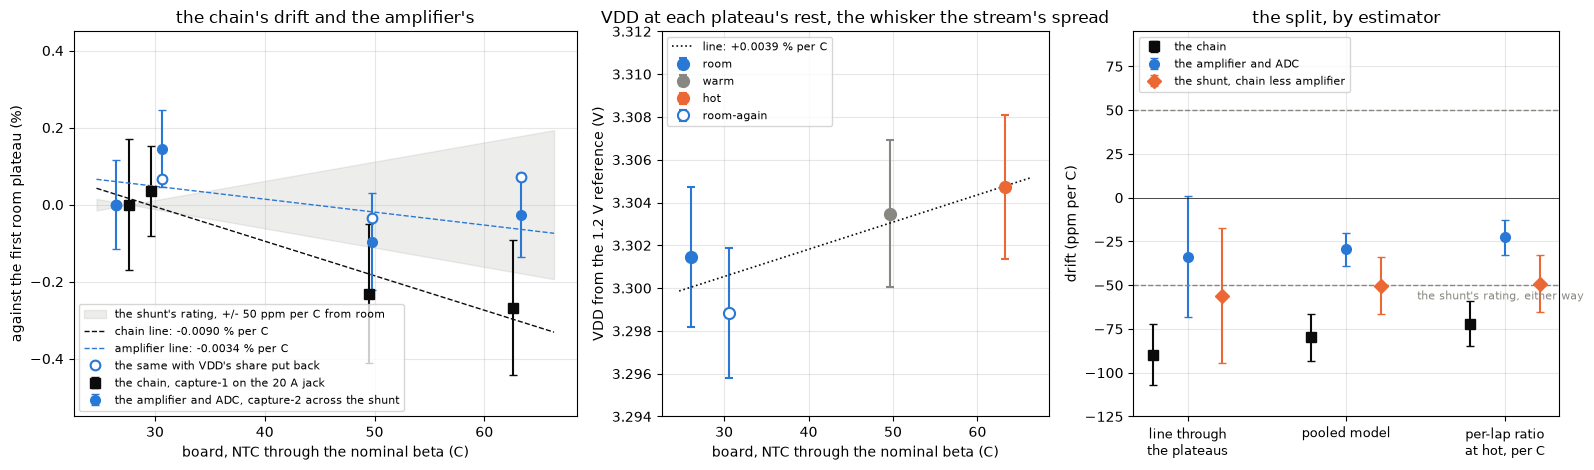

In [11]:
g2 = laps.line(P2["board_c"], P2["amp_pct"])                         # the amplifier's drift per degree, a line through the four plateaus
T0_2 = P2["board_c"].iloc[0]
X2 = np.column_stack([np.ones(len(T2)), T2["mv"], T2["mv"] * (T2["board_c"] - T0_2)])   # the pooled model: n = b + A V + A c V (T - T0)
coef2, *_ = np.linalg.lstsq(X2, T2["counts"].to_numpy(float), rcond=None)
res2 = T2["counts"].to_numpy(float) - X2 @ coef2
se2 = np.sqrt(np.diag(np.linalg.inv(X2.T @ X2)) * (res2 @ res2) / (len(T2) - 3))
pooled2, pooled2_se = coef2[2] / coef2[1] * 100, se2[2] / coef2[1] * 100   # c in percent per degree, with its standard error
ratio2 = {}
for p in PLATEAUS:                                                    # each lap's counts per millivolt against the room lap at the same level and direction
    t = T2[T2["plateau"] == p].set_index(["k", "dir"])
    q_ = ((t["counts"] / t["mv"]) / (room2["counts"] / room2["mv"]) - 1) * 100
    ratio2[p] = (q_.mean(), q_.std() / np.sqrt(len(q_)))
back2 = P2["amp_pct"].iloc[3]; back2_se = np.hypot(P2["amp_pct_se"].iloc[0], P2["amp_pct_se"].iloc[3])   # room again against room, both errors in it
span2 = P2["board_c"].iloc[2] - P2["board_c"].iloc[0]
print(f"line through the four plateaus: amplifier {g2['slope']:+.4f} +/- {g2['slope_se']:.4f} % per C over {P2['board_c'].min():.0f} to {P2['board_c'].max():.0f} C, rms {g2['rms']:.3f} %")
print(f"pooled model over all forty rows, one offset: A {coef2[1]:.3f} +/- {se2[1]:.3f} counts/mV at {T0_2:.1f} C, b {coef2[0]:+.2f} +/- {se2[0]:.2f}, drift {pooled2:+.4f} +/- {pooled2_se:.4f} % per C, rms {np.sqrt((res2 ** 2).mean()):.2f} counts")
print("per-lap ratio against the room lap at the same level: " + ", ".join(f"{p} {m:+.3f} +/- {s:.3f} %" for p, (m, s) in ratio2.items()))
print(f"room again against room: {back2:+.2f} +/- {back2_se:.2f} %; hot against room {P2['amp_pct'].iloc[2]:+.2f} +/- {P2['amp_pct_se'].iloc[2]:.2f} % over {span2:.1f} C")

vrows = []
for p in PLATEAUS:                                                    # VDD at each plateau from the rest stream before its laps
    df, meta = tel.load(CAPTURE2 / p / "rest", BOARD)
    r = df[df["seg"] == 0]                                            # the two second torque-off rest; the 5 % rung after it is not used
    vref, vref_sd = r["vref_raw"].mean(), r["vref_raw"].std()
    vrows.append({"plateau": p, "rows": len(r), "missing": int(tel.gaps(r).sum()), "vref_raw": vref, "vref_sd": vref_sd,
                  "vdd_v": BOARD.vdd_v(vref), "vdd_sd_mv": (BOARD.vdd_v(vref - vref_sd) - BOARD.vdd_v(vref + vref_sd)) / 2 * 1e3,   # the stream's spread, in mV of VDD
                  "rail_v": BOARD.rail_v(r["vbus_raw"].mean(), vref), "rest_c": ntc_c(r["ntc_raw"].mean()), "zero": r["current_raw"].mean()})
V = pd.DataFrame(vrows)
V["vdd_pct"] = (V["vdd_v"] / V["vdd_v"].iloc[0] - 1) * 100            # VDD against the room plateau; the counts move by the same amount the other way
VDD_COUNT_PCT = (BOARD.vdd_v(V["vref_raw"].iloc[0] - 1) / BOARD.vdd_v(V["vref_raw"].iloc[0]) - 1) * 100   # one count of vref_raw, in percent of VDD: the reading's resolution
gv = laps.line(V["rest_c"], V["vdd_pct"])                             # VDD's drift per degree, a line through the four rests
show(V, n=None)
print(f"VDD at the four rests: " + ", ".join(f"{r['plateau']} {r['vdd_v']:.4f} V ({r['vdd_pct']:+.3f} %) at {r['rest_c']:.1f} C, spread {r['vdd_sd_mv']:.1f} mV" for _, r in V.iterrows())
      + f"; one count of vref_raw is {VDD_COUNT_PCT:.3f} % of VDD; rail {V['rail_v'].min():.3f} to {V['rail_v'].max():.3f} V")
print(f"VDD's drift: {gv['slope']:+.4f} +/- {gv['slope_se']:.4f} % per C by the line, hot against room {V['vdd_pct'].iloc[2]:+.3f} %, which takes {-V['vdd_pct'].iloc[2]:+.3f} % off the counts there")
own_hot, own_hot_se = ratio2["hot"][0] + V["vdd_pct"].iloc[2], np.hypot(ratio2["hot"][1], VDD_COUNT_PCT)   # the op-amp and its resistors alone at hot, VDD's share put back, a count of vref_raw in the error
own_c, own_c_se = g2["slope"] + gv["slope"], np.hypot(g2["slope_se"], gv["slope_se"])
print(f"the op-amp and its resistors alone: hot against room {own_hot:+.3f} +/- {own_hot_se:.3f} % by the per-lap ratio, {own_c:+.4f} +/- {own_c_se:.4f} % per C by the lines")

TCR = BOARD.shunt_tcr_ppm_per_c / 1e4                                 # the shunt's rating, 50 ppm per C either way, in percent per degree
est = {"line through\nthe plateaus": (g["slope"], g["slope_se"], g2["slope"], g2["slope_se"]),
       "pooled model": (pooled, pooled_se, pooled2, pooled2_se),
       "per-lap ratio\nat hot, per C": (ratio["hot"][0] / span, ratio["hot"][1] / span, ratio2["hot"][0] / span2, ratio2["hot"][1] / span2)}
S = pd.DataFrame([{"estimator": k.replace("\n", " "), "chain": c, "chain_se": cs, "amp": a, "amp_se": a_se, "shunt": c - a, "shunt_se": np.hypot(cs, a_se)}
                  for k, (c, cs, a, a_se) in est.items()])            # the shunt's own drift as the chain less the amplifier, errors in quadrature
for _, r in S.iterrows():
    print(f"{r['estimator']:28s} chain {r['chain'] * 1e4:+6.1f} +/- {r['chain_se'] * 1e4:4.1f} ppm/C, amplifier {r['amp'] * 1e4:+6.1f} +/- {r['amp_se'] * 1e4:4.1f}, "
          f"shunt {r['shunt'] * 1e4:+6.1f} +/- {r['shunt_se'] * 1e4:4.1f} ppm/C against a rating of +/- {BOARD.shunt_tcr_ppm_per_c}")
shunt_hot = ratio["hot"][0] - ratio2["hot"][0]; shunt_hot_se = np.hypot(ratio["hot"][1], ratio2["hot"][1])   # the shunt's own fall at hot by the per-lap ratios, the two spans two degrees apart
print(f"the shunt at hot against room by the per-lap ratios: {shunt_hot:+.2f} +/- {shunt_hot_se:.2f} % over about {span:.0f} C, rated within +/- {TCR * span:.2f} %")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1.1]})
tt = np.linspace(P["board_c"].min() - 3, P2["board_c"].max() + 3, 20)
ax[0].fill_between(tt, -TCR * (tt - T0_C), TCR * (tt - T0_C), color=MUTED, alpha=0.15, label=f"the shunt's rating, +/- {BOARD.shunt_tcr_ppm_per_c} ppm per C from room")
ax[0].errorbar(P["board_c"], P["gain_pct"], yerr=P["gain_pct_se"], fmt="s", ms=7, color=INK, capsize=3, label="the chain, capture-1 on the 20 A jack")
ax[0].plot(tt, g["slope"] * tt + g["intercept"], "--", color=INK, lw=1, label=f"chain line: {g['slope']:+.4f} % per C")
ax[0].errorbar(P2["board_c"], P2["amp_pct"], yerr=P2["amp_pct_se"], fmt="o", ms=7, color=BLUE, capsize=3, label="the amplifier and ADC, capture-2 across the shunt")
ax[0].plot(tt, g2["slope"] * tt + g2["intercept"], "--", color=BLUE, lw=1, label=f"amplifier line: {g2['slope']:+.4f} % per C")
ax[0].plot(P2["board_c"], P2["amp_pct"] + V["vdd_pct"], "o", ms=7, color=BLUE, mfc="white", mew=1.5, label="the same with VDD's share put back")
ax[0].set_ylim(-0.55, 0.45); ax[0].set_xlabel("board, NTC through the nominal beta (C)"); ax[0].set_ylabel("against the first room plateau (%)"); ax[0].set_title("the chain's drift and the amplifier's")
ax[0].legend(fontsize=8, loc="lower left")
for _, r in V.iterrows():
    ax[1].errorbar(r["rest_c"], r["vdd_v"], yerr=r["vdd_sd_mv"] / 1e3, fmt="o", ms=8, color=COLOR[r["plateau"]], mfc=FACE[r["plateau"]], mew=1.5, capsize=3, label=r["plateau"])
ax[1].plot(tt, V["vdd_v"].iloc[0] * (1 + (gv["slope"] * tt + gv["intercept"]) / 100), ":", color=INK, lw=1.2, label=f"line: {gv['slope']:+.4f} % per C")
ax[1].set_ylim(3.294, 3.312); ax[1].set_xlabel("board, NTC through the nominal beta (C)"); ax[1].set_ylabel("VDD from the 1.2 V reference (V)"); ax[1].set_title("VDD at each plateau's rest, the whisker the stream's spread")
ax[1].legend(fontsize=8, loc="upper left")
xs = np.arange(len(S))
for dx, col, mk, c_, lab in ((-0.22, "chain", "s", INK, "the chain"), (0, "amp", "o", BLUE, "the amplifier and ADC"), (0.22, "shunt", "D", ORANGE, "the shunt, chain less amplifier")):
    ax[2].errorbar(xs + dx, S[col] * 1e4, yerr=S[col + "_se"] * 1e4, fmt=mk, ms=7, color=c_, capsize=3, label=lab)
for y_ in (-BOARD.shunt_tcr_ppm_per_c, BOARD.shunt_tcr_ppm_per_c):
    ax[2].axhline(y_, color=MUTED, lw=1, ls="--")
ax[2].axhline(0, color=INK, lw=0.5)
ax[2].text(len(S) - 0.5, -BOARD.shunt_tcr_ppm_per_c - 3, "the shunt's rating, either way", fontsize=8, ha="right", va="top", color=MUTED)
ax[2].set_xticks(xs, list(est.keys()), fontsize=9); ax[2].set_ylim(-125, 95); ax[2].set_ylabel("drift (ppm per C)"); ax[2].set_title("the split, by estimator"); ax[2].legend(fontsize=8, loc="upper left")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Left, the amplifier's points sit near zero where the chain's fall away. The line through its four plateaus gives -0.0034 +/- 0.0034 % per C, the pooled model -0.0029 +/- 0.0009 and the per-lap ratios -0.06 +/- 0.02 % at warm, -0.08 +/- 0.04 % at hot and +0.01 +/- 0.02 % at room again. The per-lap ratio puts the hot plateau two standard errors under room, a third of the chain's fall, and the two room plateaus agree, so the amplifier does move a little with temperature and that estimator is the only one that sees it. The chain's line leaves the rating's wedge by the hot plateau and the amplifier's line stays inside it.

Middle, VDD from the rest streams is 3.3015 V at room, 3.3035 at warm, 3.3047 at hot and 3.2988 at room again, with 3 mV of spread within each stream and the rail at 5.50 V for all four. One count of vref_raw is 2.2 mV, 0.067 % of VDD, and the differences between plateaus are one to one and a half counts, so VDD is read here at about its own resolution. The three readings on the way up rise with temperature, +0.0039 +/- 0.0017 % per C by the line, and the room-again reading sits 2.7 mV under room with the board 4 C warmer, which that line's error carries. At the hot plateau VDD is 0.10 % over room, and counts per millivolt scale as one over VDD, so VDD takes 0.10 % off the counts there, more than the amplifier's whole fall of 0.08 %. With that share put back the op-amp and its two resistors on their own read +0.02 +/- 0.08 % at hot against room and +0.0005 +/- 0.0038 % per C, the open markers on the left, flat within a tenth of a percent.

Right, the split. The chain less the amplifier is the shunt's own resistance change, and the three estimators put it at -56 +/- 39, -50 +/- 17 and -49 +/- 16 ppm per C, the pooled model and the per-lap ratio three standard errors from zero. The part is rated 50 ppm per C either way, so the inferred drift sits at the edge of the rating, with the sign of a part whose resistance falls as it warms. Over the 35 C span that is -0.17 +/- 0.06 % by the per-lap ratios against the rating's 0.17 %. So the hypothesis is that the shunt owns about two thirds of the chain's quarter percent and VDD most of the rest, with the amplifier's own share inside a tenth of a percent, and I hold it as likely rather than established, since it rests on two sittings a day apart.

What differs between the two captures, and whether that can make the difference. The day between them, and the meter's range and class. The class divides out of each capture's ratios, and the meter's own gain holding through each hour is what the room-again returns support, +0.00 +/- 0.03 % and +0.01 +/- 0.02 % by the per-lap ratios. The 20 A jack's 1 mA steps are 0.08 % of a 1.3 A reading against 0.012 % for the 10 uV steps at 82 mV, and that is inside the first capture's residual and its standard errors already. The hot plateau at 758 counts against 743, 62.6 C against 63.4, and the room plateau at 27.7 C against 26.5, together two degrees on the span, move a per-degree slope by about 6 %, and each drift here is read per degree of its own capture's span. The load sat on the bed in both. None of that produces a 0.17 % difference at the hot plateau, so the difference is read as the shunt's, with the two-sitting caveat on it.

| Candidate for the quarter percent | What the data says | Confidence |
|---|---|---|
| The shunt's own temperature coefficient | The chain's drift less the amplifier's is -50 ppm per C by the pooled model and by the per-lap ratio, each +/- 17, and -56 +/- 39 by the lines, which is -0.17 +/- 0.06 % over the span. The part, a JIERR JER1206F1R060 metal alloy 1206, is rated 50 ppm per C either way, 0.17 % over this span, so the inferred drift sits at the rating's edge with a size the rating allows. | Likely the owner of about two thirds. Rests on two sittings a day apart. Both routes in one sitting, or a reference shunt in the loop, settles it. |
| The ADC's reference, VDD, moving with temperature | The rest streams read VDD 3 mV, 0.10 %, over room at the hot plateau, to about a count of vref_raw, and the three readings on the way up rise with temperature. That takes 0.10 % off the counts on both routes, most of the amplifier's 0.08 % and a third of the chain's 0.25 %. The zero's +0.17 % move the other way is the amplifier's offset, as the first capture read it. | Likely about a third, read at the resolution of the reference. A longer rest, or the reference against a known rail, reads it to better than a count. |
| The amplifier's gain, its two resistors and the op-amp | With VDD's share put back the amplifier reads +0.02 +/- 0.08 % at hot against room and +0.0005 +/- 0.004 % per C. The earlier characterization current-scale cites had a sister board's amplifier alone drift a quarter percent over 28 to 60 C, read the same way across the shunt pads, and this board does not show that. That data is not here to compare. | Unlikely as more than a tenth of a percent on this board. |
| The meter reading differently at the warm and hot plateaus | Each route sat on one range at room through its run, the class divides out of the ratios, and the room-again return on both routes is within 0.03 %. The two routes see the same shape, a fall at the heated plateaus that comes back, with different sizes. | Unlikely. Both routes in one sitting checks it. |
| The load's 1 % fall in current | Moves the x axis on both routes, not the line. | Does not enter. |
| The offset moving with temperature, read as gain over a short current range | The offsets agree within their errors on both routes, and the pooled models with one offset give the same drifts as the lines with free offsets. | Unlikely. |

### The NTC under drive

The ntc-curve notebook left open whether the board's own heat moves the NTC. Each lap here has a one second torque-off rest before its first drive and the NTC in every row at the control rate, so the count's change from that rest through the two driven segments is the drive's heat reaching the NTC, and the rest of the next lap says whether it kept moving in the gap. Left, the raw count through the room plateau's five laps on the host clock, the driven segments shaded, each lap's segments placed at their nominal offsets inside the sweep. Right, the move within each lap, the last 300 ms of the second drive against the rest before the first, in degrees through the nominal beta, against the lap's current, for all four plateaus. The thing to see is whether the count falls while the bridge drives and by how much.

,plateau,k,volts_set,amps,rest,rest_sd,drive_1,drive_2,end,minutes,in_lap_counts,in_lap_c,gap_counts
0,room,0,3.700,0.641,1940.049,0.966,1940.207,1940.154,1940.021,0.065,-0.028,0.001,-1.438
1,room,1,4.500,0.782,1938.583,0.984,1938.172,1936.581,1936.026,0.333,-2.556,0.057,-3.381
2,room,2,5.500,0.958,1932.646,1.005,1931.966,1929.759,1929.099,0.606,-3.547,0.080,-4.090
3,room,3,7.200,1.256,1925.008,1.002,1923.952,1919.884,1918.665,0.872,-6.343,0.143,-7.370
4,room,4,7.600,1.325,1911.295,0.888,1909.915,1904.474,1902.820,1.150,-8.475,0.191,NaN
5,warm,0,3.700,0.637,1107.589,0.713,1107.018,1106.063,1105.467,11.688,-2.123,0.069,-5.087
6,warm,1,4.500,0.774,1100.380,0.681,1100.651,1101.150,1101.764,12.020,1.384,-0.045,-3.796
7,warm,2,5.500,0.950,1097.968,0.773,1097.068,1096.078,1095.763,12.360,-2.206,0.072,-1.060
8,warm,3,7.200,1.243,1094.703,0.639,1094.132,1093.478,1093.091,12.693,-1.612,0.053,-12.514
9,warm,4,7.600,1.311,1080.577,0.694,1079.919,1079.569,1079.611,13.036,-0.965,0.032,NaN


room       rest before the first lap 1940, before the last 1911 counts (+0.65 C over 1.1 min); within the 7.6 V lap -8.5 counts = +0.19 C; through the gaps -1.4, -3.4, -4.1, -7.4 counts
warm       rest before the first lap 1108, before the last 1081 counts (+0.89 C over 1.3 min); within the 7.6 V lap -1.0 counts = +0.03 C; through the gaps -5.1, -3.8, -1.1, -12.5 counts
hot        rest before the first lap 759, before the last 757 counts (+0.06 C over 1.4 min); within the 7.6 V lap -6.4 counts = +0.30 C; through the gaps +4.2, -2.0, -2.9, +0.5 counts
room-again rest before the first lap 1843, before the last 1832 counts (+0.25 C over 1.1 min); within the 7.6 V lap -5.8 counts = +0.13 C; through the gaps +0.3, -0.5, -2.5, -5.7 counts
the curve's slope: -45 counts per C at room, -22 at the hot plateau; the rest's sd 0.6 to 1.0 counts


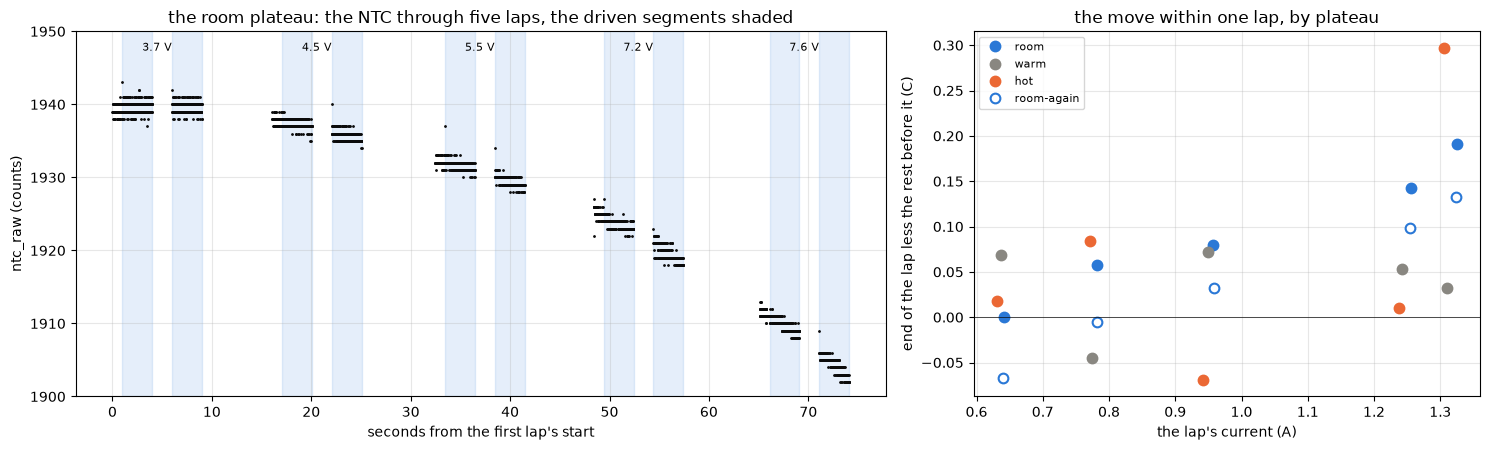

In [12]:
rows = []
for _, L in levels.iterrows():
    df, meta = tel.load(CAPTURE / L["plateau"] / L["folder"])
    b = tel.baseline(df)                                              # the second half of the rest before the lap
    s2 = df[df["seg"] == 2]
    rows.append({"plateau": L["plateau"], "k": int(L["k"]), "volts_set": L["volts_set"], "amps": T[(T["plateau"] == L["plateau"]) & (T["k"] == L["k"])]["amps"].mean(),
                 "rest": b["ntc_raw"].mean(), "rest_sd": b["ntc_raw"].std(), "drive_1": df[df["seg"] == 1]["ntc_raw"].mean(), "drive_2": s2["ntc_raw"].mean(),
                 "end": s2["ntc_raw"].iloc[-6000:].mean(), "minutes": tm(L["t_start"])})   # the last 300 ms of the second drive
N = pd.DataFrame(rows)
N["in_lap_counts"] = N["end"] - N["rest"]                             # the move within the lap, counts
N["in_lap_c"] = ntc_c(N["end"]) - ntc_c(N["rest"])                    # the same in degrees, the curve's slope at that count
N["gap_counts"] = N.groupby("plateau")["rest"].shift(-1) - N["end"]   # the next lap's rest less this lap's end: the move through the gap with the bridge off
show(N, n=None)
for p in PLATEAUS:
    n_ = N[N["plateau"] == p]
    print(f"{p:10s} rest before the first lap {n_['rest'].iloc[0]:.0f}, before the last {n_['rest'].iloc[-1]:.0f} counts ({ntc_c(n_['rest'].iloc[-1]) - ntc_c(n_['rest'].iloc[0]):+.2f} C over {n_['minutes'].iloc[-1] - n_['minutes'].iloc[0]:.1f} min); "
          f"within the 7.6 V lap {n_['in_lap_counts'].iloc[-1]:+.1f} counts = {n_['in_lap_c'].iloc[-1]:+.2f} C; through the gaps " + ", ".join(f"{v:+.1f}" for v in n_['gap_counts'].dropna()) + " counts")
print(f"the curve's slope: {1 / (ntc_c(1929) - ntc_c(1928)):.0f} counts per C at room, {1 / (ntc_c(759) - ntc_c(758)):.0f} at the hot plateau; the rest's sd {N['rest_sd'].min():.1f} to {N['rest_sd'].max():.1f} counts")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
gr = trace[trace["plateau"] == "room"]
for _, L in levels[levels["plateau"] == "room"].iterrows():        # the driven segments of each lap, shaded
    for s in (1, 2):
        ax[0].axvspan(L["t_start"] + SEG_T0[s] - levels["t_start"].min(), L["t_start"] + SEG_T0[s] + 3 - levels["t_start"].min(), color=BLUE, alpha=0.12)
    ax[0].text(L["t_start"] + 4.5 - levels["t_start"].min(), 0.97, f"{L['volts_set']:g} V", fontsize=8, ha="center", va="top", transform=ax[0].get_xaxis_transform())
ax[0].plot(gr["t_host"] - levels["t_start"].min(), gr["ntc_raw"], ".", ms=2, color=INK)
ax[0].set_ylim(gr["ntc_raw"].min() - 2, gr["ntc_raw"].max() + 7)     # headroom for the level names over the first lap
ax[0].set_xlabel("seconds from the first lap's start"); ax[0].set_ylabel("ntc_raw (counts)"); ax[0].set_title("the room plateau: the NTC through five laps, the driven segments shaded"); ax[0].grid(alpha=0.3)
for p in PLATEAUS:
    n_ = N[N["plateau"] == p]
    ax[1].plot(n_["amps"], n_["in_lap_c"], ls="none", marker="o", ms=7, color=COLOR[p], mfc=FACE[p], mew=1.5, label=p)
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xlabel("the lap's current (A)"); ax[1].set_ylabel("end of the lap less the rest before it (C)")
ax[1].set_title("the move within one lap, by plateau"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

At the room plateau the count falls through every driven segment and more at the higher levels, 8.5 counts within the 7.6 V lap, which is 0.19 C at the curve's slope there, and it keeps falling through the gap after each lap with the bridge off, 1 to 7 counts and more after the higher levels, so the heat reaches the NTC a few seconds behind the drive. From the rest before the first lap to the rest before the last the count falls 29 counts, 0.65 C, over 80 s of laps. The room-again plateau shows the same shape at 0.13 C within the 7.6 V lap and 0.25 C across the laps. At the two heated plateaus the move within a lap is a few counts of either sign at most levels, with the hot 7.6 V lap at 0.30 C, and the bed's regulation is cycling by a degree every ten seconds under the board there, so the drive's signal is in the bed's noise at warm and partly out of it at hot. One thing in the warm plateau does not fit either story. Its rest before the 7.6 V lap sits 12.5 counts under the end of the 7.2 V lap, 0.41 C in seven seconds with the bridge off, where the other gaps at that plateau move 1 to 5 counts. It is noted and not explained, and the host's one register read during the warm laps is the only other thing that happened there.

So the board's own heat under drive does move the NTC, by a few tenths of a degree per 9 W lap at room and up to two thirds of a degree over five laps, with a lag of seconds, with high confidence at the room plateaus. The ntc-curve capture ran with the bridge off, so none of that is in its curve, and a board temperature read from the NTC during or just after a hard drive sits a few tenths over the rest reading. Where the heat comes from is open. At 1.3 A the feed diode drops about 0.25 V for 0.3 W, the bridge and the shunt together about as much, all on the board, and the load's 9 W went into the bed under the board. The experiment that separates them is under Open questions.

### The results file

The chain's drift per degree from the line through the four plateaus with its standard error as the bounds, the pooled model's drift beside it, the zero's drift per degree, the largest drift, the copper it reads as, the range covered, the return at room again, and the NTC's move under drive, all from the first capture. From the second, the amplifier's drift per degree by the line and by the pooled model, its drift at the hot plateau, VDD's drift per degree, and the shunt's inferred drift as the chain less the amplifier, by the line and at the hot plateau. The per-lap ratios at the hot plateau for the chain, the amplifier and the shunt sit beside them, the ones that resolve the split. Each plateau's board temperature with its spread over the laps, raw count, gain, offset, zero and drift in `plateaus` for the first capture, and the same with the amplifier's counts per millivolt and VDD in `plateaus_rs1` for the second. `results.write` names one capture, so `capture` stays the first and the notes name the second.

In [13]:
q = results.quantity
plateaus = {r["plateau"]: {"board_c": q(r["board_c"], r["c_lo"], r["c_hi"], "C"), "ntc_raw": q(r["ntc_raw"], unit="counts"),
                           "gain_counts_per_a": q(r["gain"], r["gain"] - r["gain_se"], r["gain"] + r["gain_se"], "counts/A"),
                           "offset_counts": q(r["offset"], r["offset"] - r["offset_se"], r["offset"] + r["offset_se"], "counts"),
                           "zero_counts": q(r["zero"], r["zero_lo"], r["zero_hi"], "counts"), "gain_pct": q(r["gain_pct"], r["gain_pct"] - r["gain_pct_se"], r["gain_pct"] + r["gain_pct_se"], "%"),
                           "residual_rms_counts": q(r["rms"], unit="counts")} for _, r in P.iterrows()}
n_room = N[N["plateau"].isin(["room", "room-again"])]
over_laps = {p: ntc_c(N[N["plateau"] == p]["rest"].iloc[-1]) - ntc_c(N[N["plateau"] == p]["rest"].iloc[0]) for p in ("room", "room-again")}   # first rest to last rest, in degrees
plateaus_rs1 = {r["plateau"]: {"board_c": q(r["board_c"], r["c_lo"], r["c_hi"], "C"), "ntc_raw": q(r["ntc_raw"], unit="counts"),
                               "amp_counts_per_mv": q(r["amp"], r["amp"] - r["amp_se"], r["amp"] + r["amp_se"], "counts/mV"),
                               "offset_counts": q(r["offset"], r["offset"] - r["offset_se"], r["offset"] + r["offset_se"], "counts"),
                               "zero_counts": q(r["zero"], r["zero_lo"], r["zero_hi"], "counts"), "amp_pct": q(r["amp_pct"], r["amp_pct"] - r["amp_pct_se"], r["amp_pct"] + r["amp_pct_se"], "%"),
                               "residual_rms_counts": q(r["rms"], unit="counts"),
                               "vdd_v": q(v["vdd_v"], v["vdd_v"] - v["vdd_sd_mv"] / 1e3, v["vdd_v"] + v["vdd_sd_mv"] / 1e3, "V"), "rest_c": q(v["rest_c"], unit="C")}
                for (_, r), (_, v) in zip(P2.iterrows(), V.iterrows())}   # the second capture's plateaus, the rest stream's VDD with the stream's spread as lo/hi
S_ = S.set_index("estimator")
ratio_hot = S_.loc["per-lap ratio at hot, per C"]                     # the per-lap ratio at the hot plateau, per degree of each capture's own span
results.write("1-board", "opamp-temperature", CAPTURE, pair=BOARD.key,
              notes=f"DC laps on the bare load at four plateaus of a printer bed, the load on the bed too, meter route {route} on the 20 A range at room in capture-1, "
                    f"and the same laps a day later in {results.rel(CAPTURE2)} on route {route2}, the meter on the 220 mV range across the Rs1 pads, with a rest stream "
                    "of the chip's 1.2 V reference at a 5.5 V rail before each plateau's laps; one line per plateau "
                    "through counts over the lap's own zero against the meter's amps; gain_drift_pct_per_c is the line through the four plateaus' gain_pct against "
                    "the board NTC through ntc-curve's beta_nominal, its design conversion, with its standard error as the bounds, gain_drift_pooled_pct_per_c the one-offset "
                    "model over all forty rows; a plateau's board_c is the mean over its laps' drives with the spread over the laps as lo/hi, and beyond that it carries "
                    f"ntc-curve's grade, the meter's class of 1 % + 0.5 C and the bed gradient, {grad_hot:.1f} C at the hot plateau; "
                    "gain_drift_max_pct is the hot plateau against room; reversibility_pct is room-again against room with both errors; ntc_move_in_lap_c is the "
                    "NTC's fall through the 7.6 V lap at the room plateaus, ntc_move_over_laps_c the fall from the first lap's rest to the last's there; "
                    "amp_drift_pct_per_c and amp_drift_pooled_pct_per_c are the same two estimators on capture-2's counts per millivolt of shunt, the amplifier and the ADC "
                    "with the shunt out of the route, amp_drift_max_pct its hot plateau against room; vdd_v per plateau in plateaus_rs1 is the rest stream's mean with the stream's "
                    "spread as lo/hi, read to about a count of vref_raw, and vdd_drift_pct_per_c the line through the four; shunt_drift_pct_per_c is gain_drift_pct_per_c less "
                    "amp_drift_pct_per_c with the errors in quadrature, the shunt's own resistance change, shunt_drift_max_pct the same at the hot plateau, against the "
                    f"part's rating of {BOARD.shunt_tcr_ppm_per_c} ppm per C either way; the *_hot_ratio_pct_per_c keys are the per-lap ratio at the hot plateau over each capture's own "
                    "room to hot span, the estimator that resolves the split; the two captures are a day apart on the same board and rig",
              gain_drift_pct_per_c=q(g["slope"], g["slope"] - g["slope_se"], g["slope"] + g["slope_se"], "%/C"),
              gain_drift_pooled_pct_per_c=q(pooled, pooled - pooled_se, pooled + pooled_se, "%/C"),
              gain_drift_per_100_counts_pct=q(rl["slope"] * 100, (rl["slope"] - rl["slope_se"]) * 100, (rl["slope"] + rl["slope_se"]) * 100, "%/100 counts"),
              zero_drift_counts_per_c=q(z["slope"], z["slope"] - z["slope_se"], z["slope"] + z["slope_se"], "counts/C"),
              gain_drift_max_pct=q(P["gain_pct"].iloc[2], P["gain_pct"].iloc[2] - P["gain_pct_se"].iloc[2], P["gain_pct"].iloc[2] + P["gain_pct_se"].iloc[2], "%"),
              copper_error_max_c=q(P["copper_c"].iloc[2], unit="C"),
              copper_error_c_per_c=q(g["slope"] / COPPER_PCT_PER_C, unit="C/C"),
              range_c=q(P["board_c"].max(), P["board_c"].min(), P["board_c"].max(), "C"),
              reversibility_pct=q(back, back - back_se, back + back_se, "%"),
              ntc_move_in_lap_c=q(n_room[n_room["volts_set"] == 7.6]["in_lap_c"].mean(), n_room[n_room["volts_set"] == 7.6]["in_lap_c"].min(), n_room[n_room["volts_set"] == 7.6]["in_lap_c"].max(), "C"),
              ntc_move_over_laps_c=q(over_laps["room"], min(over_laps.values()), max(over_laps.values()), "C"),
              amp_drift_pct_per_c=q(g2["slope"], g2["slope"] - g2["slope_se"], g2["slope"] + g2["slope_se"], "%/C"),
              amp_drift_pooled_pct_per_c=q(pooled2, pooled2 - pooled2_se, pooled2 + pooled2_se, "%/C"),
              amp_drift_max_pct=q(P2["amp_pct"].iloc[2], P2["amp_pct"].iloc[2] - P2["amp_pct_se"].iloc[2], P2["amp_pct"].iloc[2] + P2["amp_pct_se"].iloc[2], "%"),
              amp_reversibility_pct=q(back2, back2 - back2_se, back2 + back2_se, "%"),
              vdd_drift_pct_per_c=q(gv["slope"], gv["slope"] - gv["slope_se"], gv["slope"] + gv["slope_se"], "%/C"),
              shunt_drift_pct_per_c=q(S_.loc["line through the plateaus", "shunt"], S_.loc["line through the plateaus", "shunt"] - S_.loc["line through the plateaus", "shunt_se"],
                                      S_.loc["line through the plateaus", "shunt"] + S_.loc["line through the plateaus", "shunt_se"], "%/C"),
              shunt_drift_max_pct=q(P["gain_pct"].iloc[2] - P2["amp_pct"].iloc[2], P["gain_pct"].iloc[2] - P2["amp_pct"].iloc[2] - np.hypot(P["gain_pct_se"].iloc[2], P2["amp_pct_se"].iloc[2]),
                                    P["gain_pct"].iloc[2] - P2["amp_pct"].iloc[2] + np.hypot(P["gain_pct_se"].iloc[2], P2["amp_pct_se"].iloc[2]), "%"),
              shunt_tcr_rating_pct_per_c=q(TCR, -TCR, TCR, "%/C"),
              gain_hot_ratio_pct_per_c=q(ratio_hot["chain"], ratio_hot["chain"] - ratio_hot["chain_se"], ratio_hot["chain"] + ratio_hot["chain_se"], "%/C"),
              amp_hot_ratio_pct_per_c=q(ratio_hot["amp"], ratio_hot["amp"] - ratio_hot["amp_se"], ratio_hot["amp"] + ratio_hot["amp_se"], "%/C"),
              shunt_hot_ratio_pct_per_c=q(ratio_hot["shunt"], ratio_hot["shunt"] - ratio_hot["shunt_se"], ratio_hot["shunt"] + ratio_hot["shunt_se"], "%/C"),
              plateaus=plateaus, plateaus_rs1=plateaus_rs1)

PosixPath('stages/1-board/opamp-temperature/results/dev-v006-2A-D.json')

## Limitations

- The two routes ran a day apart, so the split of the drift between the shunt and the amplifier rests on two sittings and not on one, and on the meter's own gain holding through each hour, which each capture's room-again return supports and does not prove. A sitting with both routes, the meter moved between the 20 A jack and the shunt pads at each plateau, reads the split in one hour.
- The load sat on the heated bed in both captures, against the procedure. Its current fell 1 to 1.5 % at the heated plateaus, which the fit against the meter does not see, and its 9 W per lap went into the bed under the board, which the NTC section does not separate from the board's own heat.
- Four plateaus, two of them near room, over 28 to 63 C on the first route and 26 to 63 C on the second. The line through four points has two degrees of freedom and its standard error is what four points give. The per-plateau gains carry 0.17 % each on the chain and 0.10 to 0.13 % on the amplifier, the size of the signal or more, and each drift is read from the four together and the per-lap ratios, not from any one plateau. The amplifier's drift is resolved by the per-lap ratios and the pooled model only.
- A plateau temperature through the nominal beta carries ntc-curve's grade, the meter's class of 1 % plus 0.5 C, 1.1 C at the hot plateau, and the bed gradient that notebook names, the top surface under the NTC's copper by about 1.1 C with the bed 18 C over the board, about 2 C together and about 6 % on the per-degree slope. The drift against the raw count is free of it.
- The first capture's first plateau sat at 28 C by the NTC, not at the room's 24 C, since the bed was still warm from the earlier run, and the second capture's at a true room, 26 C, with the room-again plateaus at 30 and 31 C. The spans are 35 and 37 C, and the lowest temperature a servo meets is not in either.
- The first capture's hot plateau was held eight minutes from the bed's step and settled at a raw count of 758, the second's fourteen minutes and 743, against 730 at ntc-curve's hot plateau with the same setpoint held longer. The board moved under a degree across each plateau's laps in both.
- VDD is read to about a count of vref_raw, 2.2 mV or 0.07 %, which is the size of the differences between plateaus. The room-again rest reads 2.7 mV under room with the board 4 C warmer, so VDD's drift per degree is a bracket and not a number, and its 0.10 % share of the amplifier's drift at the hot plateau carries that count. The ADC's own linearity over the four codes the reference crossed is not in the error.
- The bed's own log did not record in the second capture, so that run's setpoint changes are placed by the marks and the bench notes. The log is a side note on the rig and never a reference, so nothing here reads it.
- A host process read the NTC register once during the first capture's warm laps, a watch loop that was then stopped. Every segment of every lap in both captures reports no missing rows, so no harm is seen. The 12 count step in that plateau's last rest is noted in the NTC section and stays unexplained.
- The meter bounds every absolute gain, at 2 % plus 25 mA on the 20 A jack and 0.1 % plus 50 uV on the millivolt range. The drift between plateaus on either route is bounded by the fit's standard error, as said in the method.
- One board, one run per route. The run to run spread of either drift is not known.

## Open questions

- The shunt's share in one sitting. The two routes alternated at each plateau, the meter moved between the 20 A jack and the shunt pads lap by lap, read the split without a day and a range change between its two halves, and say whether the -0.17 % the difference gives is the shunt's or the two sittings'. A 0.1 % reference shunt in series on the millivolt range grades the shunt's own value and its drift directly, which is also what current-scale left open.
- VDD against temperature at better than a count. A rest stream long enough to average the reference past its own quantization, or the reference read against a rail the DPS sets and the meter reads, says whether the regulator's output rises 3 mV from room to 63 C as the three readings on the way up say, or sits flat within a count as the room-again reading says.
- Whether the drift is linear in temperature or settles. A longer hot soak, the laps repeated every ten minutes at one setpoint, says whether the gain keeps moving once the NTC has stopped, which would point to a part warming slower than the NTC does.
- Where the heat that moves the NTC under drive comes from. The same laps with the load off the bed on longer leads, the bed off, and the NTC streamed for a minute after the last lap, separate the load's heat through the bed from the board's own and give the lag directly. A swap board without the feed diode, or the rail fed past the diode, takes the diode's share out.
- The run to run spread on one route. A repeat of either capture on the same rig gives it.
- The drift below room. A plateau with the board cooled toward 10 C, a cold pack or a cold room, extends the line to the low end a servo meets.

## Conclusion

The current chain's gain on board D falls 0.23 % at 50 C and 0.27 % at 63 C against 28 C, and comes back to +0.03 % at 30 C, so the drift is the temperature's and not the hour's, with high confidence from the per-lap ratios, which put the hot plateau five standard errors under room. The line through the four plateaus gives -0.0090 +/- 0.0017 % per C, the pooled model over all forty rows -0.0080 +/- 0.0014, and the same reading against the raw count is 0.027 % per 100 counts. Read as copper, the whole excursion is -0.7 C of winding temperature over 35 C of board, under a degree, and the winding thermometer's ratio over a hold that warms the board by ten degrees reads the winding 0.23 C cold from the chain alone. The in-drive offset is +5 to +6 counts at every plateau and does not move with temperature within its 2 count error. The torque-off zero moves +0.06 counts per C, 2 counts over the span, which a zero taken at rest before each drive follows.

The amplifier and the ADC alone, read across the shunt pads a day later, move much less. Each plateau's line gives 18.63, 18.61, 18.62 and 18.65 counts per millivolt of shunt at 26, 50, 63 and 31 C, each +/- 0.02, and the per-lap ratios put the hot plateau 0.08 +/- 0.04 % under room, with the line through the four plateaus at -0.0034 +/- 0.0034 % per C and the pooled model at -0.0029 +/- 0.0009. VDD from the rest streams is 3.30 V at every plateau and about 3 mV, 0.10 %, higher at the hot plateau than at room, read to about a count of the reference, which on its own takes 0.10 % off the counts there, so the op-amp and its two resistors are flat within a tenth of a percent over the span with VDD's share put back. The chain's drift less the amplifier's is the shunt's own, about -50 ppm per C by each of the three estimators, +/- 17 on the two that resolve it, at the edge of the part's 50 ppm per C rating and -0.17 +/- 0.06 % over the span. So the shunt likely owns about two thirds of the quarter percent and VDD most of the rest, from two sittings a day apart, and the earlier characterization's quarter percent for a sister board's amplifier alone is not what this board shows.

The board's own heat under drive moves the NTC, by 0.19 C through one 9 W lap at room and 0.65 C from the first lap's rest to the last over five laps, with a lag of seconds, which answers ntc-curve's question and puts a few tenths of a degree between the NTC during a hard drive and the board at rest.

Later stages take `gain_drift_pct_per_c` from the result file for a board temperature correction if one is ever wanted, and more likely take the finding as a bound, a quarter percent over the range a board meets on a bench. The split says what such a correction would be correcting, the shunt's own tempco at its rating's edge in `shunt_drift_pct_per_c` and VDD's rise in `vdd_drift_pct_per_c`, with the op-amp and its resistors inside a tenth of a percent. A correction built on the shunt's share waits for a reference shunt in the loop or both routes in one sitting, since the split here rests on two.